# E14-H76 - conditioned centering probe

**Author**: Konrad Jelen (kj)<br>
**Date**: 2026-10-09<br>
**Pipeline stage**: experiment, measurement only - the pre-pass of the shipped source-conditioned path swapped between three arms, everything downstream held fixed

**Purpose**. E12-H64 and E14-H75 measured on two symmetric panels that mean-centering plus re-L2-normalisation
carries the whole margin gain of the shipped `all_but_the_top(k=1)` (`src/docdistance/distance.py:94-115`).
Acceptance criterion ACC-GEOM-21 would replace the shipped pre-pass with centering alone. The source-conditioned
path estimates the pre-pass from one triple - a document, the anchor and the source, about 90 statements of
which 70 are source statements - and E14-H75 read there, without a bar, a `D_sel` at 0.330 to 0.493 times the
shipped value on three triples. This notebook measures with a registered bar whether centering alone is
interchangeable with the shipped pre-pass on the conditioned selection axis.

**Arms** (the estimation pool in every arm is the triple `{document, anchor, source}`)

- **raw** - `compute_source_conditioned(..., anisotropy=False)`: no pre-pass
- **shipped** - `compute_source_conditioned(..., anisotropy=True)`: the shipped `all_but_the_top(k=1)`
- **a - center + renorm** - the pooled triple is mean-centered and re-L2-normalised outside the function, which is then called with `anisotropy=False`; no SVD

**Panel**. The 11 ibm executive summaries against the anchor `exec-summary-gold-opus-4-6.md`, with the source
`source-article.md` (70 statements), on the shipped OpenVINO INT8 mmBERT. `D_sel` is read per document from the
shipped `compute_source_conditioned`, called without the reranker and entailment arrays.

$$\mathrm{DR}(D_{sel}) = \operatorname{std}_{\,l \neq \text{anchor}} \; D_{sel}(l,\ \text{anchor} \mid S)$$

$$V_{sel} = \#\{(g, a) : g \in \text{gold tier},\ a \in \text{adversarial tier},\ D_{sel}(g) \ge D_{sel}(a)\}$$

Both are the E04-H15 definitions. They are quoted from the E04 notebook in the section after the configuration,
in a markdown cell that precedes every measurement cell.

**Approach**
1. **Definitions** - the two E04-H15 definitions quoted, and a text check that the functions scored here are the E04 text
2. **Kill-gate** - on the shipped INT8 path with the per-triple pool, DR(`D_sel`) of the shipped pre-pass at least 1.5x the raw arm at 0 violations
3. **Harness readings** - the shipped arm against the saved 1.1.5 results, the replacement route bit for bit, and the argument order of the two documents
4. **Registered experiment** - the three arms on the 10 non-anchor documents: `D_sel`, DR, violations, the DR ratio of arm a to the shipped arm
5. **Readings without a bar** - Spearman of `D_sel` between arm a and shipped, the gold-to-adversarial contrast, closeness and residual to the source, the pool geometry, what the first principal component separates in the source, the Wergeland source with its three sections
6. **Guardrails** - `V` 0/24 on the ibm symmetric panel, raw embeddings byte-identical after every arm, default-path `smd` and `order_gap` bit-identical, `D_grd` untouched, metric property, `src/` and `tests/` unmodified
7. **Prediction check and acceptance bar** - Confirmed (not interchangeable) iff DR(`D_sel`) under arm a is below 0.9x the shipped arm or arm a reads at least one violation; Refuted (interchangeable) iff arm a reads 0 violations and at least 0.9x

**Decision rule recorded with the bar**. ACC-GEOM-21 changes the conditioned-path pre-pass only on Refuted. On
Confirmed the shipped pre-pass stays.

**Output**: `reports/E14-H76-conditioned-centering-probe-metrics.json`

## Environment

CPU only: the campaign primer keeps stage A on CPU, so CUDA is masked before any import. `CI=true` switches
the OpenVINO usage telemetry off, and the models resolve offline through the repo's `docdistance.json`.

In [1]:
import os
import logging
import warnings

os.environ["CUDA_VISIBLE_DEVICES"] = ""       # CPU only: no GPU is used in stage A
os.environ["CI"] = "true"                     # OpenVINO usage telemetry off (DEF-DEPS-11)
os.environ["TOKENIZERS_PARALLELISM"] = "false"
os.environ["TRANSFORMERS_VERBOSITY"] = "error"
os.environ["HF_HUB_DISABLE_PROGRESS_BARS"] = "1"
os.environ["HF_HUB_DISABLE_TELEMETRY"] = "1"

warnings.filterwarnings("ignore")
for _n in ("torch", "transformers", "huggingface_hub", "openvino", "wtpsplit"):
    logging.getLogger(_n).setLevel(logging.ERROR)

print("device: CPU (CUDA masked)")

device: CPU (CUDA masked)


## Imports

All imports in one cell. The shipped `docdistance` functions are imported and never edited: arm a is built
inside this notebook. Autoreload is left off, because a measurement run must score one fixed copy of the
shipped code from the first cell to the last.

In [2]:
# Standard library
import gzip                        # reads the captured 1.1.5 baseline
import hashlib                     # sha256 of the grounding-signals file, before and after
import inspect                     # source text of the scored definitions, for the quote check
import itertools                   # the 55 ibm document pairs and the 3 Wergeland section pairs
import json                        # fixture, baseline, E04 notebook and metrics files
import struct                      # float64 → its 8 bytes, for byte-level comparison
import subprocess                  # git status for the source-tree guardrail
from collections import Counter    # repeated one-word source statements
from pathlib import Path

# Numerics
import numpy as np                 # arm a, SVD, panel statistics
import ot                          # POT, the transport solver behind D_sel and smd
from scipy.stats import spearmanr  # rank agreement of D_sel between arms

# Plotting
import matplotlib.pyplot as plt    # inline figures, object-oriented API

# Output
from rich.console import Console, Group   # one rendered block per result
from rich.markup import escape            # statement text and git output printed as literal text
from rich.panel import Panel
from rich.progress import track           # progress bar on the encode loops
from rich.table import Table

# Shipped code under measurement
import docdistance
from docdistance.distance import (
    all_but_the_top,               # the shipped pre-pass
    closeness,                     # 1 - d / sqrt(2), clipped at 0
    compute_distance,              # default-path smd
    compute_source_conditioned,    # the conditioned path under measurement
    compute_structural,            # default-path order_gap
    cost_matrix,                   # ground cost sqrt(2 - 2cos)
    coverage_alignment,            # per-statement soft assignment over the source
    coverage_profile,              # mean assignment of a document over the source
    grounding_residual,            # D_grd residual from the reranker and entailment arrays
    selection_divergence,          # D_sel between two coverage profiles
    smd,                           # exact Statement Mover's Distance
)
from docdistance.pipeline import DocDistance   # shipped reader, SaT segmenter and OpenVINO INT8 encoder

console = Console(width=150)
print(f"docdistance {docdistance.__version__} | POT {ot.__version__} | numpy {np.__version__}\n"
      f"package: {Path(docdistance.__file__).parent}")

docdistance 1.1.5 | POT 0.9.6.post1 | numpy 2.4.6
package: /home/lab/workspace/learning/projects/docdistance/src/docdistance


## Reproducibility

One fixed seed. No step samples: OpenVINO INT8 inference on CPU, an exact network-simplex transport solve
and a numpy SVD are deterministic, so a re-execution reproduces every reading.

In [3]:
SEED = 42
np.random.seed(SEED)
print(f"SEED={SEED}")

SEED=42


## Configuration

Fixture paths, the document registry, the three arms, and the registered kill-gate, bar and prediction
numbers. This cell executes before every measurement cell. Where the record leaves a reading rule open, the
rule is the executor's and is stated here.

- **Argument order (executor's rule)** - the record names the pool `{document, anchor, source}`, so the bar reading calls the shipped function with `a` = document and `b` = anchor. `closeness_a` and `residual_a` are then the document's readings. `reports/E13-campaign/baseline.py` and E14-H75 call it with `a` = anchor; that order is scored as a second reading and reported beside the bar reading
- **Violation orderings** - the E04 definition counts over 28 orderings, because its `gold_labels` list holds the anchor. The bar is read on that count. The count over the 24 orderings without the anchor is reported beside it
- **Harness rule (executor's rule)** - the comparison is read only when the shipped arm reproduces the three saved 1.1.5 results bit for bit and the pre-pass built outside the function reproduces the internal one bit for bit. A failure of either gives `Blocked`. The rule can withhold a verdict; it cannot change which branch of the bar is met
- **Metric-property tolerances (executor's rule)** - the E12-H64 reading: unit norms to `1e-6`, `cost = sqrt(2 - 2cos)` to `1e-6` in float64 on copies re-normalised to exact unit length, triangle slack to `1e-9`. The record names no tolerance
- **Counterfactual word rules (executor's rule, no bar)** - the section on the first principal component was added after the first execution of this notebook showed the PC1 share of the centered variance. Its two rules for removing source statements were chosen with those outputs in view: fewer than 2 words (the one-word statements) and fewer than 5 words (the rule E13-H72 reports). No kill-gate, bar or verdict field reads them

In [4]:
ROOT = Path("/home/lab/workspace/learning/projects/docdistance")                           # repo root
IBM_DIR = ROOT / "data/interim/exec-summaries/ibm-ai-adoption"                              # summaries and source
WERG_SOURCE_PATH = ROOT / "data/interim/ai-society-wergeland/source/source-article.md"      # second source, no bar
STATEMENTS_PATH = ROOT / "data/processed/structure-fixture/statements.json"                 # the three Wergeland sections
SIGNALS_PATH = ROOT / "data/interim/E12-H69-grounding-signals.npz"                          # model-graded signals, D_grd guardrail
BASELINE_PATH = ROOT / "reports/E13-campaign/baseline/default-path.json.gz"                 # 1.1.5 readings captured at bd0002e
E04_NOTEBOOK = ROOT / "notebooks/experiments/E04-kj-source-conditioned-performance.ipynb"   # origin of the quoted definitions
METRICS_PATH = ROOT / "reports/E14-H76-conditioned-centering-probe-metrics.json"

# ibm panel (file, label, tier), the E04 registry; the order is kept
DOCS = [
    ("exec-summary-gold-opus-4-6.md",     "gold",   "gold"),    # anchor
    ("exec-summary-gold-2-opus-4-6.md",   "gold-2", "gold"),
    ("exec-summary-1-opus-4-6.md",        "v1",     "gold"),
    ("exec-summary-2-opus-4-6.md",        "v2",     "gold"),
    ("exec-summary-opus-4-6.md",          "opus",   "gold"),
    ("exec-summary-sonnet-4-6.md",        "sonnet", "gold"),
    ("exec-summary-haiku-4-5.md",         "haiku",  "gold"),
    ("exec-summary-adv1-a-sonnet-4-6.md", "adv1-a", "adv1"),
    ("exec-summary-adv1-b-sonnet-4-6.md", "adv1-b", "adv1"),
    ("exec-summary-adv2-a-haiku-4-5.md",  "adv2-a", "adv2"),
    ("exec-summary-adv2-b-haiku-4-5.md",  "adv2-b", "adv2"),
]
REFERENCE = "gold"                                                  # the anchor label
TIER = {label: tier for (_, label, tier) in DOCS}
STEM = {l: f.removeprefix("exec-summary-").removesuffix(".md") for f, l, _ in DOCS}    # baseline.py keys
BASELINE_TRIPLES = [("gold", "v1"), ("gold", "adv1-a"), ("gold", "adv2-b")]            # saved results, (anchor, document)
N_SUMMARY_STATEMENTS, N_SOURCE_STATEMENTS = 98, 70                  # counts of this environment (E14-H75, baseline)

# second source (no bar): the Wergeland article and its three sections
WERG_SECTIONS = ["werg-a", "werg-b", "werg-c"]
WERG_EXPECTED_N = {"werg-a": 11, "werg-b": 13, "werg-c": 14}        # registered statement counts
WERG_PAIRS = list(itertools.combinations(WERG_SECTIONS, 2))         # three triples with the Wergeland source

# arms
RAW, SHIPPED, ARM_A = "raw", "shipped", "a center+renorm"
ARMS = [RAW, SHIPPED, ARM_A]
K = 1                                # the shipped setting, all_but_the_top(k=1)
COND_FIELDS = ("d_sel", "residual_a", "residual_b", "closeness_a", "closeness_b")
SMD_MAX = float(np.sqrt(2.0))        # closeness() clips to 0 at or above this distance

# kill-gate (registered): the E04-H15 acceptance bar on the shipped INT8 path, per-triple pool
GATE_MIN_DR_RATIO = 1.5              # DR(D_sel) shipped at least this multiple of the raw arm
GATE_VIOLATIONS = 0                  # at this many selection-axis violations in the shipped arm

# acceptance bar (registered)
BAR_DR_RATIO = 0.9                   # arm a below this multiple of the shipped DR: not interchangeable
BAR_MIN_VIOLATIONS = 1               # or arm a reads at least this many violations: not interchangeable

# prediction (registered)
PRED_VIOLATIONS = 0                  # selection-axis violations in each of the three arms
PRED_A_BAND = (0.3, 0.9)             # DR(D_sel) under arm a as a multiple of the shipped arm

# numbers the record cites from E14-H75, printed beside the readings of this notebook
RECORD_COS_CENTERED_PC1_MEAN = 0.056        # cos(centered PC1, mean direction) on its 76-statement symmetric pool
RECORD_H75_DSEL_RATIO = (0.330, 0.493)      # D_sel arm a / shipped on three ibm triples

# readings without a bar (executor's rules): source statements with fewer words than the rule are removed
FRAGMENT_MIN_WORDS = 2               # the one-word statements; the rule of the shipped opt-in filter min_words=2
COUNTERFACTUAL_MIN_WORDS = (FRAGMENT_MIN_WORDS, 5)   # second rule: fewer than 5 words, the rule E13-H72 reports

# standing guardrail: the naive row of the ibm symmetric panel in the campaign primer
PRIMER_NAIVE = {"margin_pts": 4.71, "dprime": 4.68, "R": 1.670, "DR": 0.0873, "V": 0}

# metric-property tolerances (the E12-H64 reading)
NORM_TOL = 1e-6                      # unit norms
COST_ID_TOL = 1e-6                   # cost = sqrt(2 - 2cos), float64 on exact-unit copies
TRI_TOL = 1e-9                       # triangle-inequality slack over every statement triple

# semantic colours, one palette for every figure; markers and hatches repeat the encoding
C_GOLD, C_ADV = "#2ECC71", "#E74C3C"                                         # gold tier, bar met | adversarial tier, bar missed
ARM_COLOR = {RAW: "#7F8C8D", SHIPPED: "#3498DB", ARM_A: "#9B59B6"}           # no pre-pass | shipped pre-pass | arm a
ARM_HATCH = {RAW: "", SHIPPED: "//", ARM_A: ".."}
C_DOC_STMT, C_SRC_STMT, C_ONE_WORD = "#34495E", "#16A085", "#E67E22"         # document | source, 2 words or more | source, one word

NOT_RUN = "[dark_goldenrod]not run - the kill-gate fired or a harness reading failed[/dark_goldenrod]"
METRICS = {"id": "E14-H76", "slug": "conditioned-centering-probe"}   # every section adds its block
KEY = {}                                                             # key numbers for the campaign result JSON

cfg = Table(title="E14-H76 configuration", header_style="bold medium_purple")
cfg.add_column("group", style="grey70"); cfg.add_column("key"); cfg.add_column("value", style="bold")
for group, key, value in [
    ("fixture", "ibm panel", f"{len(DOCS)} summaries, anchor {REFERENCE}, source source-article.md ({N_SOURCE_STATEMENTS} statements)"),
    ("fixture", "pool", "per triple: document + anchor + source, the shipped pool"),
    ("fixture", "second source", f"Wergeland article with {', '.join(WERG_SECTIONS)} ({len(WERG_PAIRS)} triples, no bar)"),
    ("models", "encoder", "mmBERT OpenVINO INT8 (CPU), the shipped default"),
    ("arms", "raw", "compute_source_conditioned(anisotropy=False)"),
    ("arms", "shipped", f"compute_source_conditioned(anisotropy=True): all_but_the_top(k={K})"),
    ("arms", ARM_A, "pooled triple centered and re-L2-normalised here, then anisotropy=False"),
    ("kill-gate", "DR(D_sel) shipped / raw", f"kill below {GATE_MIN_DR_RATIO}"),
    ("kill-gate", "violations, shipped arm", f"kill above {GATE_VIOLATIONS}"),
    ("bar", "Confirmed (not interchangeable)", f"DR(D_sel) arm a below {BAR_DR_RATIO}x shipped, or arm a reads at least "
                                               f"{BAR_MIN_VIOLATIONS} violation"),
    ("bar", "Refuted (interchangeable)", f"arm a reads 0 violations and DR(D_sel) arm a at least {BAR_DR_RATIO}x shipped"),
    ("prediction", "clauses", f"{PRED_VIOLATIONS} violations in all three arms | shipped at least {GATE_MIN_DR_RATIO}x raw | "
                              f"arm a between {PRED_A_BAND[0]}x and {PRED_A_BAND[1]}x shipped"),
    ("record", "numbers cited from E14-H75", f"cos(centered PC1, mean direction) {RECORD_COS_CENTERED_PC1_MEAN} | D_sel arm a / shipped "
                                             f"{RECORD_H75_DSEL_RATIO[0]:.3f} to {RECORD_H75_DSEL_RATIO[1]:.3f} on three triples"),
    ("no bar", "counterfactual source (executor's rules)", "source statements with fewer than "
                                                           f"{COUNTERFACTUAL_MIN_WORDS[0]} words removed, and with fewer than "
                                                           f"{COUNTERFACTUAL_MIN_WORDS[1]} words removed"),
    ("guardrails", "standing", "V 0/24 on the ibm symmetric panel | no edit under src/ | metric property"),
    ("guardrails", "registered", "default-path smd and order_gap bit-identical | raw embeddings byte-identical | D_grd untouched"),
    ("guardrails", "tolerances (executor's rule)", f"unit norm {NORM_TOL:.0e} | cost identity {COST_ID_TOL:.0e} | triangle slack {TRI_TOL:.0e}"),
    ("harness", "executor's rule", "shipped arm equals the saved 1.1.5 results and the outside pre-pass equals the internal one, else Blocked"),
    ("output", "metrics json", str(METRICS_PATH.relative_to(ROOT))),
]:
    cfg.add_row(group, key, value)
console.print(cfg)

                                                                E14-H76 configuration                                                                 
┏━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ group      ┃ key                                      ┃ value                                                                                      ┃
┡━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│ fixture    │ ibm panel                                │ 11 summaries, anchor gold, source source-article.md (70 statements)                        │
│ fixture    │ pool                                     │ per triple: document + anchor + source, the shipped pool                                   │
│ fixture    │ second source                            │ Wergeland article with werg-a, werg-b, werg-c (3 triples, no bar)                          │
│ models     │ encoder                                  │ mmBERT OpenVINO INT8 (CPU), the shipped default                                            │
│ arms       │ raw                                      │ compute_source_conditioned(anisotropy=False)                                               │
│ arms       │ shipped                                  │ compute_source_conditioned(anisotropy=True): all_but_the_top(k=1)                          │
│ arms       │ a center+renorm                          │ pooled triple centered and re-L2-normalised here, then anisotropy=False                    │
│ kill-gate  │ DR(D_sel) shipped / raw                  │ kill below 1.5                                                                             │
│ kill-gate  │ violations, shipped arm                  │ kill above 0                                                                               │
│ bar        │ Confirmed (not interchangeable)          │ DR(D_sel) arm a below 0.9x shipped, or arm a reads at least 1 violation                    │
│ bar        │ Refuted (interchangeable)                │ arm a reads 0 violations and DR(D_sel) arm a at least 0.9x shipped                         │
│ prediction │ clauses                                  │ 0 violations in all three arms | shipped at least 1.5x raw | arm a between 0.3x and 0.9x   │
│            │                                          │ shipped                                                                                    │
│ record     │ numbers cited from E14-H75               │ cos(centered PC1, mean direction) 0.056 | D_sel arm a / shipped 0.330 to 0.493 on three    │
│            │                                          │ triples                                                                                    │
│ no bar     │ counterfactual source (executor's rules) │ source statements with fewer than 2 words removed, and with fewer than 5 words removed     │
│ guardrails │ standing                                 │ V 0/24 on the ibm symmetric panel | no edit under src/ | metric property                   │
│ guardrails │ registered                               │ default-path smd and order_gap bit-identical | raw embeddings byte-identical | D_grd       │
│            │                                          │ untouched                                                                                  │
│ guardrails │ tolerances (executor's rule)             │ unit norm 1e-06 | cost identity 1e-06 | triangle slack 1e-09                               │
│ harness    │ executor's rule                          │ shipped arm equals the saved 1.1.5 results and the outside pre-pass equals the internal    │
│            │                                          │ one, else Blocked                                                                          │
│ output     │ metrics json                             │ reports/E14-H76-

## E04-H15 definitions, quoted

The kill-gate and the acceptance bar are read with two quantities that E04-H15 defined. Both are quoted here
from `notebooks/experiments/E04-kj-source-conditioned-performance.ipynb` (section "Baseline and metric helpers",
code cell 14), character for character. This markdown cell precedes every measurement cell of the notebook.

**Dynamic range, `DR(D_sel)`**

```python
def DR(score):                       # dynamic range: std of the non-anchor -> ref distances
    return float(np.std([score[l] for l in NONANCHOR]))
```

**Selection-axis violation count**

```python
def violations(score):
    return sum(1 for g in gold_labels for a in adv_labels if score[g] >= score[a]), len(gold_labels) * len(adv_labels)
```

**The names the two definitions read**, from the same cell

```python
ANCHOR = REFERENCE
labels = list(docs)
gold_labels = [l for l in labels if TIER[l] == "gold"]
adv_labels = [l for l in labels if TIER[l] != "gold"]
NONANCHOR = [l for l in labels if l != ANCHOR]
```

**The score both are applied to**, from the same cell

```python
d_sel = {l: selection_divergence(docs[ANCHOR]["cov"], docs[l]["cov"], S_emb) for l in labels}
```

How the two definitions read

- `score` maps each of the 11 summary labels to its `D_sel` against the anchor
- `DR` is the population standard deviation (`np.std`, no degrees-of-freedom correction) of the 10 non-anchor values
- `violations` returns a pair: the count, and the number of orderings it ran over. `gold_labels` holds every label of tier `gold`, the anchor included, so the count runs over 7 x 4 = 28 orderings. The anchor's own score is its `D_sel` against itself. The count over the 24 orderings without the anchor is printed beside it
- E04-H15 applied them as `ratio=DR(dselk) / DR0` with the bar `ratio >= DR_BAR` (1.5) over the rows with `viol == 0`: the kill-gate of this notebook is that bar

One difference is registered in the E14-H76 record and is not a change of definition. E04 estimated the
pre-pass once from the pool of all 11 summaries plus the source and built every coverage profile in that one
geometry. The shipped `compute_source_conditioned` estimates it per call from the triple
`{document, anchor, source}`, and that per-triple pool is what this notebook scores. The E04 pool is read
without a bar in a later section.

The gold-to-adversarial contrast reported without a bar is the E04 helper of the same cell:

```python
def contrast(score):                 # scale-free gold -> adversarial spread on the axis
    g = np.mean([score[l] for l in NONANCHOR if TIER[l] == "gold"])
    a = np.mean([score[l] for l in labels if TIER[l] != "gold"])
    return float(a / g) if g > 0 else float("inf")
```

The code cell below defines the three functions with the quoted text and checks each one against the source
of the E04 notebook. It computes no measurement.

In [5]:
ANCHOR = REFERENCE
labels = [label for (_, label, _) in DOCS]         # E04: labels = list(docs), a dict filled in DOCS order
gold_labels = [l for l in labels if TIER[l] == "gold"]
adv_labels = [l for l in labels if TIER[l] != "gold"]
NONANCHOR = [l for l in labels if l != ANCHOR]
GOLD_NONANCHOR = [l for l in gold_labels if l != ANCHOR]     # not an E04 name: the 6 gold-tier documents scored against the anchor


def violations(score):
    return sum(1 for g in gold_labels for a in adv_labels if score[g] >= score[a]), len(gold_labels) * len(adv_labels)


def DR(score):                       # dynamic range: std of the non-anchor -> ref distances
    return float(np.std([score[l] for l in NONANCHOR]))


def contrast(score):                 # scale-free gold -> adversarial spread on the axis
    g = np.mean([score[l] for l in NONANCHOR if TIER[l] == "gold"])
    a = np.mean([score[l] for l in labels if TIER[l] != "gold"])
    return float(a / g) if g > 0 else float("inf")

In [6]:
e04_code = "\n".join("".join(c["source"]) for c in json.loads(E04_NOTEBOOK.read_text(encoding="utf-8"))["cells"]
                     if c["cell_type"] == "code")
QUOTE_CHECK = {fn.__name__: inspect.getsource(fn).strip() in e04_code for fn in (violations, DR, contrast)}
NAME_LINES = ['ANCHOR = REFERENCE', 'gold_labels = [l for l in labels if TIER[l] == "gold"]',
              'adv_labels = [l for l in labels if TIER[l] != "gold"]', 'NONANCHOR = [l for l in labels if l != ANCHOR]']
NAMES_CHECK = {ln: ln in e04_code for ln in NAME_LINES}
DEFINITIONS_VERBATIM = all(QUOTE_CHECK.values()) and all(NAMES_CHECK.values())
METRICS["definitions"] = {
    "origin": str(E04_NOTEBOOK.relative_to(ROOT)), "functions_equal_e04_text": QUOTE_CHECK,
    "name_lines_in_e04_text": all(NAMES_CHECK.values()), "verbatim": DEFINITIONS_VERBATIM,
    "labels": labels, "gold_labels": gold_labels, "adv_labels": adv_labels, "nonanchor": NONANCHOR,
    "violation_orderings": len(gold_labels) * len(adv_labels),
    "violation_orderings_without_anchor": len(GOLD_NONANCHOR) * len(adv_labels),
}
console.print(Panel(
    f"scored functions equal the E04 text: " + " | ".join(f"{k} {v}" for k, v in QUOTE_CHECK.items()) + "\n"
    f"the {len(NAME_LINES)} name lines are in the E04 text: {all(NAMES_CHECK.values())}\n"
    f"gold_labels ({len(gold_labels)}, the anchor included): {', '.join(gold_labels)}\n"
    f"adv_labels ({len(adv_labels)}): {', '.join(adv_labels)} | NONANCHOR ({len(NONANCHOR)} documents)\n"
    f"violation orderings: {len(gold_labels) * len(adv_labels)} by the E04 definition, "
    f"{len(GOLD_NONANCHOR) * len(adv_labels)} without the anchor",
    title="E04-H15 definitions - text check, no measurement",
    border_style="dark_sea_green" if DEFINITIONS_VERBATIM else "indian_red"))
assert DEFINITIONS_VERBATIM, "a scored definition differs from the E04 text"

╭───────────────────────────────────────────────── E04-H15 definitions - text check, no measurement ─────────────────────────────────────────────────╮
│ scored functions equal the E04 text: violations True | DR True | contrast True                                                                     │
│ the 4 name lines are in the E04 text: True                                                                                                         │
│ gold_labels (7, the anchor included): gold, gold-2, v1, v2, opus, sonnet, haiku                                                                    │
│ adv_labels (4): adv1-a, adv1-b, adv2-a, adv2-b | NONANCHOR (10 documents)                                                                          │
│ violation orderings: 28 by the E04 definition, 24 without the anchor                                                                               │
╰────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────╯

## Fixture - load and encode

The 11 ibm summaries, the ibm source and the Wergeland source go through the shipped reader, SaT segmenter and
OpenVINO INT8 encoder (`DocDistance.embed_statements`), the route `distance_wrt_source` takes. The three
Wergeland sections are read as stored statement lists and encoded with the same encoder. The counts are
checked against this environment's known values: 98 summary statements, 70 source statements, and 11, 13 and
14 statements in the sections.

In [7]:
dd = DocDistance()        # backend openvino, offline: the shipped default pipeline
encoder = dd.encoder      # first access loads the SaT segmenter and the OpenVINO INT8 mmBERT encoder
all_statements = json.loads(STATEMENTS_PATH.read_text(encoding="utf-8"))
print(f"encoder: {type(encoder).__name__} | segmenter: {type(dd.segmenter).__name__}")

encoder: OpenVINOEncoder | segmenter: Segmenter


In [8]:
texts, emb = {}, {}
for fname, label, _ in track(DOCS, description="segment and encode the ibm summaries", console=console):
    texts[label], emb[label] = dd.embed_statements(IBM_DIR / "summaries" / fname)

In [9]:
source_texts, S = dd.embed_statements(IBM_DIR / "source" / "source-article.md")     # the ibm source
werg_source_texts, S_W = dd.embed_statements(WERG_SOURCE_PATH)                       # the Wergeland source
emb_w = {}
for key in track(WERG_SECTIONS, description="encode the Wergeland sections", console=console):
    emb_w[key] = encoder.encode(all_statements[key]["statements"])

In [10]:
N_SUMMARY = sum(len(emb[l]) for l in labels)
WERG_COUNTS_OK = all(len(emb_w[k]) == n and all_statements[k]["article"] == "wergeland" for k, n in WERG_EXPECTED_N.items())
FIXTURE_OK = bool(N_SUMMARY == N_SUMMARY_STATEMENTS and len(S) == N_SOURCE_STATEMENTS and WERG_COUNTS_OK)
POOL_N = {l: len(emb[l]) + len(emb[ANCHOR]) + len(S) for l in NONANCHOR}       # statements in each triple
WERG_COMMENT_STATEMENTS = sum(("<!--" in t) or ("-->" in t) for t in werg_source_texts)
WERG_HEADING_STATEMENTS = sum(t.lstrip().startswith("#") for t in werg_source_texts)

METRICS["fixture"] = {
    "ibm_statements_by_doc": {l: len(emb[l]) for l in labels}, "ibm_summary_statements": N_SUMMARY,
    "ibm_source_statements": len(S), "pool_statements_by_doc": POOL_N,
    "source_share_of_pool_min": min(len(S) / n for n in POOL_N.values()),
    "source_share_of_pool_max": max(len(S) / n for n in POOL_N.values()),
    "wergeland_source_statements": len(S_W), "wergeland_section_statements": {k: len(emb_w[k]) for k in WERG_SECTIONS},
    "wergeland_source_statements_with_html_comment_marker": int(WERG_COMMENT_STATEMENTS),
    "wergeland_source_statements_starting_with_hash": int(WERG_HEADING_STATEMENTS),
    "encoder": "mmBERT OpenVINO INT8 (CPU)", "docdistance_version": docdistance.__version__, "fixture_ok": FIXTURE_OK,
}
KEY.update(n_documents=len(NONANCHOR), n_source_statements=len(S), pool_statements_min=min(POOL_N.values()),
           pool_statements_max=max(POOL_N.values()), source_share_of_pool_min=min(len(S) / n for n in POOL_N.values()),
           source_share_of_pool_max=max(len(S) / n for n in POOL_N.values()))

tbl = Table(title=f"ibm panel - {N_SUMMARY} summary statements, {len(S)} source statements", header_style="bold medium_purple")
for col, just in [("document", "left"), ("tier", "left"), ("statements", "right"), ("pool of its triple", "right"),
                  ("source share of the pool", "right"), ("first statement", "left")]:
    tbl.add_column(col, justify=just)
for l in labels:
    pool = "-" if l == ANCHOR else str(POOL_N[l])
    share = "-" if l == ANCHOR else f"{len(S) / POOL_N[l]:.3f}"
    tbl.add_row(f"{l} (anchor)" if l == ANCHOR else l, TIER[l], str(len(emb[l])), pool, share, escape(texts[l][0][:60]))
console.print(Group(tbl, Panel(
    f"summary statements {N_SUMMARY} (expected {N_SUMMARY_STATEMENTS}) | ibm source statements {len(S)} (expected {N_SOURCE_STATEMENTS})\n"
    f"pool per triple: {min(POOL_N.values())} to {max(POOL_N.values())} statements, source share "
    f"{min(len(S) / n for n in POOL_N.values()):.3f} to {max(len(S) / n for n in POOL_N.values()):.3f}\n"
    f"Wergeland source through the shipped reader: {len(S_W)} statements, of which {WERG_COMMENT_STATEMENTS} carry an HTML "
    f"comment marker and {WERG_HEADING_STATEMENTS} start with a hash | sections "
    + ", ".join(f"{k} {len(emb_w[k])}" for k in WERG_SECTIONS) + f" (counts match the record: {WERG_COUNTS_OK})",
    title="fixture checks", border_style="dark_sea_green" if FIXTURE_OK else "indian_red")))
assert FIXTURE_OK, "fixture does not match the registered counts"

                                              ibm panel - 98 summary statements, 70 source statements                                               
┏━━━━━━━━━━━━━━━┳━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ document      ┃ tier ┃ statements ┃ pool of its triple ┃ source share of the pool ┃ first statement                                              ┃
┡━━━━━━━━━━━━━━━╇━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│ gold (anchor) │ gold │         10 │                  - │                        - │ Enterprise AI adoption has stalled at 42% active deployment  │
│ gold-2        │ gold │         12 │                 92 │                    0.761 │ Enterprise AI adoption has stalled at 42% active deployment  │
│ v1            │ gold │         11 │                 91 │                    0.769 │ Enterprise AI adoption has stalled at 42% active deployment  │
│ v2            │ gold │         11 │                 91 │                    0.769 │ Enterprise AI adoption has stalled at 42% active deployment  │
│ opus          │ gold │         11 │                 91 │                    0.769 │ Enterprise AI adoption has stalled at 42% active deployment  │
│ sonnet        │ gold │          9 │                 89 │                    0.787 │ Enterprise AI adoption faces a critical inflection point: 42 │
│ haiku         │ gold │         13 │                 93 │                    0.753 │ Enterprise AI deployment has reached 42% adoption among larg │
│ adv1-a        │ adv1 │          8 │                 88 │                    0.795 │ It appears that enterprise adoption of artificial intelligen │
│ adv1-b        │ adv1 │          9 │                 89 │                    0.787 │ It appears that enterprise adoption of artificial intelligen │
│ adv2-a        │ adv2 │          1 │                 81 │                    0.864 │ Contemporary enterprise-scale organizations (exceeding 1,000 │
│ adv2-b        │ adv2 │          3 │                 83 │                    0.843 │ The comprehensive IBM Global AI Adoption Index 2023, conduct │
└───────────────┴──────┴────────────┴────────────────────┴──────────────────────────┴──────────────────────────────────────────────────────────────┘
╭────────────────────────────────────────────────────────────────── fixture checks ──────────────────────────────────────────────────────────────────╮
│ summary statements 98 (expected 98) | ibm source statements 70 (expected 70)                                                                       │
│ pool per triple: 81 to 93 statements, source share 0.753 to 0.864                                                                                  │
│ Wergeland source through the shipped reader: 52 statements, of which 2 carry an HTML comment marker and 4 start with a hash | sections werg-a 11,  │
│ werg-b 13, werg-c 14 (counts match the record: True)                                                                                               │
╰────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────╯

## Arms, panels and readings

Definitions only, no measurement. `center_renorm` is arm a with the E12-H64 and E14-H75 expression.
`conditioned` calls the shipped `compute_source_conditioned` under one arm. `sel_panel` builds the E04 score
(every summary against the anchor) from those calls and reads it with the quoted definitions. The last cell
of the section snapshots the raw embeddings, the shipped default-path readings and the grounding-signals file
before any arm runs.

In [11]:
def center_renorm(pool: dict) -> dict:
    """Arm a: subtract the pooled mean and re-L2-normalise every row; no SVD (the E12-H64 and E14-H75 expression)."""
    keys = list(pool)
    stacked = np.concatenate([pool[k] for k in keys], 0)
    centered = stacked - stacked.mean(0)
    fixed = centered / (np.linalg.norm(centered, axis=1, keepdims=True) + 1e-9)
    out, off = {}, 0
    for k in keys:
        n = len(pool[k])
        out[k] = fixed[off:off + n].astype(np.float32)
        off += n
    return out


def arm_arrays(pool: dict, arm: str) -> dict:
    """The embeddings one arm hands to the coverage profile; the estimation pool is ``pool`` in every arm."""
    if arm == RAW:
        return pool
    if arm == SHIPPED:
        return all_but_the_top(pool, k=K)
    return center_renorm(pool)


def conditioned(triple: dict, arm: str, **grounding):
    """Shipped ``compute_source_conditioned`` on one triple ``{a, b, s}`` under one arm."""
    if arm == SHIPPED:                       # the pre-pass inside the shipped function
        return compute_source_conditioned(triple["a"], triple["b"], triple["s"], anisotropy=True, **grounding)
    fixed = arm_arrays(triple, arm)          # raw: the triple itself | arm a: the pre-pass built here
    return compute_source_conditioned(fixed["a"], fixed["b"], fixed["s"], anisotropy=False, **grounding)


def fields(res) -> dict:
    """The five embedding-driven numbers of a SourceConditionedResult."""
    return {f: getattr(res, f) for f in COND_FIELDS}


def ibm_triple(label: str, source: np.ndarray) -> dict:
    """The per-triple pool {document, anchor, source} in the argument order (a, b, s) of the shipped function."""
    return {"a": emb[label], "b": emb[ANCHOR], "s": source}

In [12]:
def score_panel(by_label: dict) -> dict:
    """The E04-H15 readings of one arm from the per-label result fields."""
    score = {l: by_label[l]["d_sel"] for l in labels}
    v, v_total = violations(score)
    gold = [score[l] for l in GOLD_NONANCHOR]
    adv = [score[l] for l in adv_labels]
    return dict(fields=by_label, d_sel=score, DR=DR(score), V=int(v), V_total=int(v_total),
                V_without_anchor=sum(1 for g in gold for a in adv if g >= a),
                V_without_anchor_total=len(gold) * len(adv),
                sel_margin=float(min(adv) - max(gold)), contrast=contrast(score))


def sel_panel(arm: str, source: np.ndarray) -> dict:
    """D_sel of every summary against the anchor under one arm: a = document, b = anchor (the registered order)."""
    return score_panel({l: fields(conditioned(ibm_triple(l, source), arm)) for l in labels})


def sel_panel_swapped(arm: str) -> dict:
    """The same panel with the two documents exchanged: a = anchor, b = document (the baseline.py order)."""
    return score_panel({l: fields(conditioned({"a": emb[ANCHOR], "b": emb[l], "s": S}, arm)) for l in labels})


def e04_pool_panel(arm: str) -> dict:
    """The E04 route: one pre-pass over the pool of all 11 summaries plus the source, then every profile in it."""
    fixed = arm_arrays({**{l: emb[l] for l in labels}, "__S__": S}, arm)
    cov = {l: coverage_profile(fixed[l], fixed["__S__"]) for l in labels}
    score = {l: selection_divergence(cov[ANCHOR], cov[l], fixed["__S__"]) for l in labels}
    v, v_total = violations(score)
    return dict(d_sel=score, DR=DR(score), V=int(v), V_total=int(v_total), contrast=contrast(score))


def symmetric_panel(eb: dict) -> dict:
    """The primer's ibm symmetric panel: smd of every non-anchor summary to the anchor, V over 6 gold x 4 adversarial."""
    dist = {l: smd(eb[l], eb[ANCHOR]) for l in NONANCHOR}
    g = np.array([dist[l] for l in GOLD_NONANCHOR])
    a = np.array([dist[l] for l in adv_labels])
    gc = np.array([closeness(d) for d in g])
    ac = np.array([closeness(d) for d in a])
    pooled = float(np.sqrt((g.var() + a.var()) / 2)) or 1e-9
    return dict(dist=dist, V=int(sum(1 for gg in g for aa in a if gg >= aa)), V_total=len(g) * len(a),
                margin_pts=float(gc.min() - ac.max()) * 100.0, dprime=float((a.mean() - g.mean()) / pooled),
                R=float(a.mean() / g.mean()), DR=float(np.concatenate([g, a]).std()))


def spearman_d_sel(panel_x: dict, panel_y: dict) -> float:
    """Spearman rank correlation of D_sel over the 10 non-anchor documents."""
    return float(spearmanr([panel_x["d_sel"][l] for l in NONANCHOR], [panel_y["d_sel"][l] for l in NONANCHOR]).statistic)


def rank_of(panel: dict) -> dict:
    """Rank of each non-anchor document by D_sel, 1 = nearest to the anchor."""
    order = sorted(NONANCHOR, key=lambda l: panel["d_sel"][l])
    return {l: order.index(l) + 1 for l in NONANCHOR}

In [13]:
def hexf(x: float) -> str:
    """The 8 bytes of a float64 as hex: equal strings are bit-identical values."""
    return struct.pack("<d", x).hex()


def default_path(eb: dict, pairs: list) -> dict:
    """Shipped default-path readings (anisotropy off) per pair: (smd bytes, order_gap bytes)."""
    return {f"{a}|{b}": (hexf(compute_distance(eb[a], eb[b]).smd), hexf(compute_structural(eb[a], eb[b]).order_gap))
            for a, b in pairs}


def raw_unchanged() -> bool:
    """True when every raw embedding array still has the bytes of its snapshot."""
    return all(RAW_ARRAYS[k].tobytes() == RAW_BYTES[k] for k in RAW_BYTES)


def run_arm(arm: str) -> None:
    """Score one arm on the ibm panel, then compare every raw embedding with its snapshot."""
    PANEL[arm] = sel_panel(arm, S)
    RAW_UNCHANGED_AFTER[arm] = raw_unchanged()
    ARMS_RUN.append(arm)


def centered_pc1(triple: dict) -> tuple:
    """Pooled mean, singular values, first principal direction and per-statement coordinate of the centered pool."""
    pool = np.concatenate([triple["a"], triple["b"], triple["s"]], 0)
    mean = pool.mean(0)
    centered = pool - mean
    _, sv, Vt = np.linalg.svd(centered, full_matrices=False)
    return mean, sv, Vt[0], centered @ Vt[0]


def pool_geometry(triple: dict) -> dict:
    """Mean norm, centered PC1 against the mean direction, PC1 variance share and the source share of PC1 energy."""
    mean, sv, pc1, coord = centered_pc1(triple)
    n_s = len(triple["s"])
    return dict(n_pool=len(coord), source_share=n_s / len(coord), mean_norm=float(np.linalg.norm(mean)),
                cos_centered_pc1_mean=float(abs(pc1 @ (mean / np.linalg.norm(mean)))),
                pc1_variance_share=float(sv[0] ** 2 / (sv ** 2).sum()),
                pc1_energy_source_share=float((coord[-n_s:] ** 2).sum() / (coord ** 2).sum()))


def signed_pc1_coord(triple: dict) -> np.ndarray:
    """Centered-PC1 coordinate of every pooled statement, sign fixed so that the document statements average negative."""
    coord = centered_pc1(triple)[3]
    n_s = len(triple["s"])
    return coord * -np.sign(coord[:-n_s].mean())


def pc1_groups(triple: dict, one_word: np.ndarray) -> dict:
    """Lowest and highest signed PC1 coordinate of three statement groups of one triple."""
    coord = signed_pc1_coord(triple)
    n_s = len(triple["s"])
    doc, src = coord[:-n_s], coord[-n_s:]
    return {"documents": (float(doc.min()), float(doc.max())),
            "source_two_words_or_more": (float(src[~one_word].min()), float(src[~one_word].max())),
            "source_one_word": (float(src[one_word].min()), float(src[one_word].max()))}


def offdiag_mean(C: np.ndarray) -> float:
    """Mean of a square cost matrix without its diagonal."""
    return float(C[~np.eye(len(C), dtype=bool)].mean())


def mean_source_cost(source: np.ndarray, rows: np.ndarray, arm: str) -> float:
    """Mean ground cost between the source statements selected by ``rows`` under one arm, averaged over the 10 triples."""
    costs = []
    for l in NONANCHOR:
        s_arm = arm_arrays(ibm_triple(l, source), arm)["s"][rows]
        costs.append(offdiag_mean(cost_matrix(s_arm, s_arm)))
    return float(np.mean(costs))


def counterfactual(min_words: int, source_words: np.ndarray) -> dict:
    """The three arms scored with the source statements of fewer than ``min_words`` words removed (same embeddings)."""
    keep = source_words >= min_words
    S_keep = S[keep]
    panels = {arm: sel_panel(arm, S_keep) for arm in ARMS}
    geo = [pool_geometry(ibm_triple(l, S_keep)) for l in NONANCHOR]
    ratio = [panels[ARM_A]["d_sel"][l] / panels[SHIPPED]["d_sel"][l] for l in NONANCHOR]
    return dict(
        min_words=min_words, source_statements=int(keep.sum()), removed=int((~keep).sum()), arms=panels,
        dr_ratio_shipped_over_raw=panels[SHIPPED]["DR"] / panels[RAW]["DR"],
        dr_ratio_arm_a_over_shipped=panels[ARM_A]["DR"] / panels[SHIPPED]["DR"],
        d_sel_ratio_arm_a_over_shipped_range=[min(ratio), max(ratio)],
        spearman_d_sel_arm_a_vs_shipped=spearman_d_sel(panels[ARM_A], panels[SHIPPED]),
        spearman_d_sel_shipped_vs_registered_shipped=spearman_d_sel(panels[SHIPPED], PANEL[SHIPPED]),
        pc1_variance_share_range=[min(g["pc1_variance_share"] for g in geo), max(g["pc1_variance_share"] for g in geo)],
        cos_centered_pc1_mean_range=[min(g["cos_centered_pc1_mean"] for g in geo), max(g["cos_centered_pc1_mean"] for g in geo)],
        mean_source_cost={arm: mean_source_cost(S_keep, np.ones(len(S_keep), dtype=bool), arm) for arm in ARMS},
    )


def coverage_readings(arrays: dict) -> dict:
    """Per document statement: nearest source statement and assignment entropy; plus the mean source ground cost."""
    A = coverage_alignment(arrays["a"], arrays["s"])                           # rows: document statements over the source
    C = cost_matrix(arrays["s"], arrays["s"])
    entropy = -(A * np.log(np.clip(A, 1e-300, None))).sum(1)
    return dict(nearest=A.argmax(1), mean_row_entropy=float(entropy.mean()),
                mean_row_max=float(A.max(1).mean()),
                mean_source_cost=offdiag_mean(C))


def metric_property(arrays: dict) -> dict:
    """Unit norms, cost = sqrt(2 - 2cos) and the triangle inequality on the pooled statements of one geometry."""
    P32 = np.concatenate([arrays["a"], arrays["b"], arrays["s"]], 0)
    norm_dev = float(np.abs(np.linalg.norm(P32, axis=1) - 1.0).max())
    P64 = P32.astype(np.float64)
    P64 = P64 / np.linalg.norm(P64, axis=1, keepdims=True)                     # exactly unit in float64
    C64 = cost_matrix(P64, P64)
    cost_id = float(np.abs(C64 - np.sqrt(np.clip(2.0 - 2.0 * (P64 @ P64.T), 0.0, None))).max())
    tri = float((C64[:, None, :] - C64[:, :, None] - C64[None, :, :]).max())   # C(i,k) - C(i,j) - C(j,k) over every triple
    n_s = len(arrays["s"])
    CS = C64[-n_s:, -n_s:]                                                     # the ground cost of D_sel
    return dict(max_unit_norm_dev=norm_dev, max_cost_identity_dev_float64=cost_id, max_triangle_slack=tri,
                min_source_offdiag_cost=float(CS[~np.eye(n_s, dtype=bool)].min()),
                holds=bool(norm_dev <= NORM_TOL and cost_id <= COST_ID_TOL and tri <= TRI_TOL))


def nearest_agreement(cov_x: dict, cov_y: dict) -> int:
    """Document statements whose nearest source statement is the same in two arms."""
    return int(sum((cov_x[l]["nearest"] == cov_y[l]["nearest"]).sum() for l in NONANCHOR))


def tier_mean(values: dict, tier_labels: list) -> float:
    """Mean of a per-document reading over one tier."""
    return float(np.mean([values[l] for l in tier_labels]))


def tier_cell(l: str) -> str:
    """The tier of a document as a coloured table cell."""
    color = "dark_sea_green" if TIER[l] == "gold" else "indian_red"
    return f"[{color}]{TIER[l]}[/{color}]"


def yn(b: bool) -> str:
    return "[dark_sea_green]yes[/dark_sea_green]" if b else "[indian_red]no[/indian_red]"


def v_text(p: dict) -> str:
    return f"{p['V']}/{p['V_total']}"

In [14]:
PANEL, ARMS_RUN, RAW_UNCHANGED_AFTER = {}, [], {}            # filled by run_arm, one entry per scored arm
RAW_ARRAYS = {**{f"ibm:{l}": emb[l] for l in labels}, "ibm:source": S, "wergeland:source": S_W,
              **{f"wergeland:{k}": emb_w[k] for k in WERG_SECTIONS}}
RAW_BYTES = {k: v.tobytes() for k, v in RAW_ARRAYS.items()}  # raw-embedding snapshot, before any arm
emb_stem = {STEM[l]: emb[l] for l in labels}
IBM_PAIRS = list(itertools.combinations(sorted(emb_stem), 2))          # the 55 pairs, keyed as baseline.py keys them
DEFAULT_BEFORE = default_path(emb_stem, IBM_PAIRS)                     # shipped smd and order_gap, before any arm
SIGNALS_SHA_BEFORE = hashlib.sha256(SIGNALS_PATH.read_bytes()).hexdigest()
with gzip.open(BASELINE_PATH, "rt", encoding="utf-8") as fh:
    baseline = json.load(fh)
_k = f"{IBM_PAIRS[0][0]}|{IBM_PAIRS[0][1]}"
console.print(Panel(
    f"raw-embedding snapshot: {len(RAW_BYTES)} arrays, {sum(len(v) for v in RAW_ARRAYS.values())} statements, "
    f"dtype {S.dtype}, dimension {S.shape[1]}\n"
    f"default-path snapshot over {len(DEFAULT_BEFORE)} ibm pairs, first pair {_k}: "
    f"smd 0x{DEFAULT_BEFORE[_k][0]}, order_gap 0x{DEFAULT_BEFORE[_k][1]}\n"
    f"grounding-signals file sha256 {SIGNALS_SHA_BEFORE[:16]}... | saved baseline: {len(baseline['pairs'])} pairs, "
    f"{len(baseline['grounded'])} source-conditioned results",
    title="snapshots taken before any arm", border_style="steel_blue"))

╭────────────────────────────────────────────────────────── snapshots taken before any arm ──────────────────────────────────────────────────────────╮
│ raw-embedding snapshot: 16 arrays, 258 statements, dtype float32, dimension 768                                                                    │
│ default-path snapshot over 55 ibm pairs, first pair 1-opus-4-6|2-opus-4-6: smd 0x2fbae8020706cf3f, order_gap 0xf85cc00a74839e3f                    │
│ grounding-signals file sha256 298b939a7450fa58... | saved baseline: 55 pairs, 3 source-conditioned results                                         │
╰────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────╯

## Kill-gate

The registered harness check on the shipped arm, taken before the comparison. On the shipped INT8 path with
the per-triple pool, DR(`D_sel`) of the shipped pre-pass must be at least 1.5x the raw arm, at 0
selection-axis violations in the shipped arm. This is the E04-H15 acceptance bar. If the shipped pre-pass does
not show that property here, the panel is not the one E04-H15 scored: the run ends with `Killed-at-gate` and
arm a is not scored.

In [15]:
for arm in (RAW, SHIPPED):
    run_arm(arm)

DR_RAW, DR_SHIPPED = PANEL[RAW]["DR"], PANEL[SHIPPED]["DR"]
DR_RATIO_SHIPPED_RAW = DR_SHIPPED / DR_RAW
GATE_DR_PASSED = bool(DR_RATIO_SHIPPED_RAW >= GATE_MIN_DR_RATIO)
GATE_V_PASSED = bool(PANEL[SHIPPED]["V"] == GATE_VIOLATIONS)
GATE_PASSED = GATE_DR_PASSED and GATE_V_PASSED
PROCEED = GATE_PASSED
HARNESS_OK = None           # set by the harness readings

METRICS["kill_gate"] = {
    "dr_raw": DR_RAW, "dr_shipped": DR_SHIPPED, "dr_ratio_shipped_over_raw": DR_RATIO_SHIPPED_RAW,
    "min_dr_ratio": GATE_MIN_DR_RATIO, "dr_reading_passed": GATE_DR_PASSED,
    "violations_shipped": PANEL[SHIPPED]["V"], "violation_orderings": PANEL[SHIPPED]["V_total"],
    "violations_shipped_without_anchor": PANEL[SHIPPED]["V_without_anchor"],
    "violation_orderings_without_anchor": PANEL[SHIPPED]["V_without_anchor_total"],
    "violations_raw": PANEL[RAW]["V"], "violations_raw_without_anchor": PANEL[RAW]["V_without_anchor"],
    "violations_reading_passed": GATE_V_PASSED, "passed": GATE_PASSED,
    "d_sel": {arm: PANEL[arm]["d_sel"] for arm in (RAW, SHIPPED)},
    "d_sel_anchor_against_itself": {arm: PANEL[arm]["d_sel"][ANCHOR] for arm in (RAW, SHIPPED)},
    "sel_margin_raw": PANEL[RAW]["sel_margin"], "sel_margin_shipped": PANEL[SHIPPED]["sel_margin"],
}
KEY.update(dr_raw=DR_RAW, dr_shipped=DR_SHIPPED, dr_ratio_shipped_over_raw=DR_RATIO_SHIPPED_RAW,
           violations_raw=PANEL[RAW]["V"], violations_shipped=PANEL[SHIPPED]["V"],
           violation_orderings=PANEL[SHIPPED]["V_total"],
           violations_raw_without_anchor=PANEL[RAW]["V_without_anchor"],
           violations_shipped_without_anchor=PANEL[SHIPPED]["V_without_anchor"],
           sel_margin_raw=PANEL[RAW]["sel_margin"], sel_margin_shipped=PANEL[SHIPPED]["sel_margin"])

t = Table(title="kill-gate - D_sel of every document against the anchor, per-triple pool", header_style="bold medium_purple")
for col in ("document", "tier", "D_sel raw", "D_sel shipped", "shipped / raw"):
    t.add_column(col, justify="left" if col in ("document", "tier") else "right")
for l in NONANCHOR:
    r, s = PANEL[RAW]["d_sel"][l], PANEL[SHIPPED]["d_sel"][l]
    t.add_row(l, tier_cell(l), f"{r:.6f}", f"{s:.6f}", f"{s / r:.3f}")
console.print(Group(t, Panel(
    f"DR(D_sel) raw = [bold]{DR_RAW:.6f}[/bold] | shipped = [bold]{DR_SHIPPED:.6f}[/bold] | shipped / raw = "
    f"[bold]{DR_RATIO_SHIPPED_RAW:.4f}[/bold]   kill below {GATE_MIN_DR_RATIO}   → {'passed' if GATE_DR_PASSED else 'KILLED'}\n"
    f"violations, shipped arm = [bold]{v_text(PANEL[SHIPPED])}[/bold] by the E04 definition "
    f"({PANEL[SHIPPED]['V_without_anchor']}/{PANEL[SHIPPED]['V_without_anchor_total']} without the anchor)   "
    f"kill above {GATE_VIOLATIONS}   → {'passed' if GATE_V_PASSED else 'KILLED'}\n"
    f"violations, raw arm = {v_text(PANEL[RAW])} ({PANEL[RAW]['V_without_anchor']}/{PANEL[RAW]['V_without_anchor_total']} "
    f"without the anchor) | lowest adversarial minus highest gold D_sel: raw {PANEL[RAW]['sel_margin']:+.6f}, "
    f"shipped {PANEL[SHIPPED]['sel_margin']:+.6f}\n"
    f"D_sel of the anchor against itself: raw {PANEL[RAW]['d_sel'][ANCHOR]:.3e}, shipped {PANEL[SHIPPED]['d_sel'][ANCHOR]:.3e}\n"
    f"gate: [bold]{'PASSED - the run proceeds' if GATE_PASSED else 'FIRED - the run ends here, verdict Killed-at-gate'}[/bold]",
    title="kill-gate", border_style="dark_sea_green" if GATE_PASSED else "indian_red")))

    kill-gate - D_sel of every document against the anchor,    
                        per-triple pool                        
┏━━━━━━━━━━┳━━━━━━┳━━━━━━━━━━━┳━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ document ┃ tier ┃ D_sel raw ┃ D_sel shipped ┃ shipped / raw ┃
┡━━━━━━━━━━╇━━━━━━╇━━━━━━━━━━━╇━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ gold-2   │ gold │  0.012867 │      0.255121 │        19.828 │
│ v1       │ gold │  0.017694 │      0.310164 │        17.530 │
│ v2       │ gold │  0.011864 │      0.201517 │        16.985 │
│ opus     │ gold │  0.012464 │      0.202030 │        16.209 │
│ sonnet   │ gold │  0.017441 │      0.252675 │        14.487 │
│ haiku    │ gold │  0.027812 │      0.370615 │        13.326 │
│ adv1-a   │ adv1 │  0.103624 │      0.805617 │         7.774 │
│ adv1-b   │ adv1 │  0.104431 │      0.813145 │         7.786 │
│ adv2-a   │ adv2 │  0.056521 │      0.529021 │         9.360 │
│ adv2-b   │ adv2 │  0.036295 │      0.413829 │        11.402 │
└──────────┴──────┴───────────┴───────────────┴───────────────┘
╭──────────────────────────────────────────────────────────────────── kill-gate ─────────────────────────────────────────────────────────────────────╮
│ DR(D_sel) raw = 0.034535 | shipped = 0.219067 | shipped / raw = 6.3433   kill below 1.5   → passed                                                 │
│ violations, shipped arm = 0/28 by the E04 definition (0/24 without the anchor)   kill above 0   → passed                                           │
│ violations, raw arm = 0/28 (0/24 without the anchor) | lowest adversarial minus highest gold D_sel: raw +0.008483, shipped +0.043215               │
│ D_sel of the anchor against itself: raw 0.000e+00, shipped 0.000e+00                                                                               │
│ gate: PASSED - the run proceeds                                                                                                                    │
╰────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────╯

## Harness readings

The record names no sanity check besides the kill-gate. Three readings show that the two arms scored above
are the shipped path and that the replacement route used for arm a is exact. The first two carry the harness
rule declared in the configuration.

- **Saved results** - the shipped call on the three triples of `reports/E13-campaign/baseline.py`, in its argument order, against the 1.1.5 results saved at commit `bd0002e`: five numbers and both coverage profiles, bit for bit
- **Replacement route** - `all_but_the_top(k=1)` applied to the pooled triple outside the function, then `anisotropy=False`, against the shipped call with `anisotropy=True`: bit for bit on all 10 triples. Arm a uses the same route with a different pre-pass
- **Argument order** - the panel with the two documents exchanged (`a` = anchor), per arm: the largest `D_sel` difference, and the gate readings recomputed

In [16]:
saved_rows = {}
for a, b in BASELINE_TRIPLES:
    res = compute_source_conditioned(emb[a], emb[b], S)          # the shipped call: default pre-pass, baseline.py order
    saved = baseline["grounded"][f"{STEM[a]}|{STEM[b]}"]
    saved_rows[f"{a}|{b}"] = dict(
        d_sel=res.d_sel, saved_d_sel=saved["d_sel"],
        fields_equal=all(hexf(getattr(res, f)) == hexf(saved[f]) for f in COND_FIELDS),
        coverage_equal=bool(res.coverage_a == saved["coverage_a"] and res.coverage_b == saved["coverage_b"]),
        counts_equal=bool((res.n_statements_a, res.n_statements_b, res.n_statements_source)
                          == (saved["n_statements_a"], saved["n_statements_b"], saved["n_statements_source"])))
BASELINE_OK = all(r["fields_equal"] and r["coverage_equal"] and r["counts_equal"] for r in saved_rows.values())

route_equal = {}
for l in NONANCHOR:
    ext = all_but_the_top(ibm_triple(l, S), k=K)                    # the pre-pass built outside the function
    via = fields(compute_source_conditioned(ext["a"], ext["b"], ext["s"], anisotropy=False))
    route_equal[l] = all(hexf(via[f]) == hexf(PANEL[SHIPPED]["fields"][l][f]) for f in COND_FIELDS)
ROUTE_OK = all(route_equal.values())

SWAPPED = {arm: sel_panel_swapped(arm) for arm in ARMS_RUN}
ORDER_DIFF = {arm: max(abs(SWAPPED[arm]["d_sel"][l] - PANEL[arm]["d_sel"][l]) for l in NONANCHOR) for arm in ARMS_RUN}
SWAPPED_RATIO_SHIPPED_RAW = SWAPPED[SHIPPED]["DR"] / SWAPPED[RAW]["DR"]
SWAPPED_GATE_SAME = bool((SWAPPED_RATIO_SHIPPED_RAW >= GATE_MIN_DR_RATIO and SWAPPED[SHIPPED]["V"] == GATE_VIOLATIONS) == GATE_PASSED)

HARNESS_OK = bool(BASELINE_OK and ROUTE_OK)
PROCEED = GATE_PASSED and HARNESS_OK

METRICS["harness"] = {
    "saved_results": saved_rows, "shipped_equals_saved_results": BASELINE_OK,
    "replacement_route_equal_by_doc": route_equal, "replacement_route_equals_shipped": ROUTE_OK,
    "argument_order": {arm: {"max_abs_d_sel_diff": ORDER_DIFF[arm], "DR": SWAPPED[arm]["DR"], "V": SWAPPED[arm]["V"],
                             "V_without_anchor": SWAPPED[arm]["V_without_anchor"], "d_sel": SWAPPED[arm]["d_sel"]}
                       for arm in ARMS_RUN},
    "argument_order_dr_ratio_shipped_over_raw": SWAPPED_RATIO_SHIPPED_RAW,
    "argument_order_gate_reading_same": SWAPPED_GATE_SAME, "passed": HARNESS_OK,
}
KEY.update(shipped_equals_saved_results=BASELINE_OK, replacement_route_equals_shipped=ROUTE_OK,
           swapped_order_dr_ratio_shipped_over_raw=SWAPPED_RATIO_SHIPPED_RAW,
           swapped_order_max_abs_d_sel_diff_raw=ORDER_DIFF[RAW], swapped_order_max_abs_d_sel_diff_shipped=ORDER_DIFF[SHIPPED])

t = Table(title="shipped call against the saved 1.1.5 results (argument order: anchor, document)", header_style="bold medium_purple")
for col in ("triple", "D_sel this run", "D_sel saved", "5 numbers bit-identical", "coverage profiles equal", "statement counts equal"):
    t.add_column(col, justify="left" if col == "triple" else "right")
for k, r in saved_rows.items():
    t.add_row(k, f"{r['d_sel']:.16f}", f"{r['saved_d_sel']:.16f}", yn(r["fields_equal"]), yn(r["coverage_equal"]), yn(r["counts_equal"]))
o = Table(title="argument order - a = anchor, b = document against the registered a = document, b = anchor", header_style="bold medium_purple")
for col in ("arm", "largest |D_sel difference|", "DR registered order", "DR exchanged order", "violations registered", "violations exchanged"):
    o.add_column(col, justify="left" if col == "arm" else "right")
for arm in ARMS_RUN:
    o.add_row(arm, f"{ORDER_DIFF[arm]:.3e}", f"{PANEL[arm]['DR']:.6f}", f"{SWAPPED[arm]['DR']:.6f}",
              v_text(PANEL[arm]), v_text(SWAPPED[arm]))
console.print(Group(t, o, Panel(
    f"shipped arm equals the saved 1.1.5 results bit for bit: [bold]{BASELINE_OK}[/bold] ({len(saved_rows)} triples)\n"
    f"pre-pass built outside the function equals the internal one bit for bit: [bold]{ROUTE_OK}[/bold] "
    f"({sum(route_equal.values())}/{len(route_equal)} triples, 5 numbers each)\n"
    f"exchanged argument order: DR shipped / raw = {SWAPPED_RATIO_SHIPPED_RAW:.4f} (registered order "
    f"{DR_RATIO_SHIPPED_RAW:.4f}) | same gate reading: {SWAPPED_GATE_SAME}\n"
    f"harness readings: [bold]{'PASSED' if HARNESS_OK else 'FAILED - verdict Blocked'}[/bold]",
    title="harness readings", border_style="dark_sea_green" if HARNESS_OK else "indian_red")))

                           shipped call against the saved 1.1.5 results (argument order: anchor, document)                            
┏━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ triple      ┃     D_sel this run ┃        D_sel saved ┃ 5 numbers bit-identical ┃ coverage profiles equal ┃ statement counts equal ┃
┡━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━┩
│ gold|v1     │ 0.3101637043342098 │ 0.3101637043342098 │                     yes │                     yes │                    yes │
│ gold|adv1-a │ 0.8056172756723156 │ 0.8056172756723156 │                     yes │                     yes │                    yes │
│ gold|adv2-b │ 0.4138294604033240 │ 0.4138294604033240 │                     yes │                     yes │                    yes │
└─────────────┴────────────────────┴────────────────────┴─────────────────────────┴─────────────────────────┴────────────────────────┘
                    argument order - a = anchor, b = document against the registered a = document, b = anchor                     
┏━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━┓
┃ arm     ┃ largest |D_sel difference| ┃ DR registered order ┃ DR exchanged order ┃ violations registered ┃ violations exchanged ┃
┡━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━┩
│ raw     │                  6.394e-09 │            0.034535 │           0.034535 │                  0/28 │                 0/28 │
│ shipped │                  8.002e-08 │            0.219067 │           0.219067 │                  0/28 │                 0/28 │
└─────────┴────────────────────────────┴─────────────────────┴────────────────────┴───────────────────────┴──────────────────────┘
╭───────────────────────────────────────────────────────────────── harness readings ─────────────────────────────────────────────────────────────────╮
│ shipped arm equals the saved 1.1.5 results bit for bit: True (3 triples)                                                                           │
│ pre-pass built outside the function equals the internal one bit for bit: True (10/10 triples, 5 numbers each)                                      │
│ exchanged argument order: DR shipped / raw = 6.3433 (registered order 6.3433) | same gate reading: True                                            │
│ harness readings: PASSED                                                                                                                           │
╰────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────╯

## Registered experiment - the three arms on the conditioned selection axis

Arm a is scored on the same 10 triples and read with the same two definitions. The bar quantity is the ratio
of DR(`D_sel`) under arm a to DR(`D_sel`) under the shipped arm, together with the violation count of arm a.
The raw embeddings are compared byte for byte with their snapshot after each arm.

$$\text{ratio}_a = \frac{\mathrm{DR}_{a}(D_{sel})}{\mathrm{DR}_{\text{shipped}}(D_{sel})}$$

In [17]:
if PROCEED:
    run_arm(ARM_A)
    SWAPPED[ARM_A] = sel_panel_swapped(ARM_A)
    ORDER_DIFF[ARM_A] = max(abs(SWAPPED[ARM_A]["d_sel"][l] - PANEL[ARM_A]["d_sel"][l]) for l in NONANCHOR)

    DR_A = PANEL[ARM_A]["DR"]
    DR_RATIO_A_SHIPPED = DR_A / DR_SHIPPED
    DR_RATIO_A_RAW = DR_A / DR_RAW
    V_A = PANEL[ARM_A]["V"]
    DSEL_RATIO = {l: PANEL[ARM_A]["d_sel"][l] / PANEL[SHIPPED]["d_sel"][l] for l in NONANCHOR}
    RANKS = {arm: rank_of(PANEL[arm]) for arm in ARMS}
    SWAPPED_RATIO_A_SHIPPED = SWAPPED[ARM_A]["DR"] / SWAPPED[SHIPPED]["DR"]
    VIOLATING_PAIRS_A = [f"{g} >= {a}" for g in gold_labels for a in adv_labels
                         if PANEL[ARM_A]["d_sel"][g] >= PANEL[ARM_A]["d_sel"][a]]

    METRICS["ibm_panel"] = {arm: PANEL[arm] for arm in ARMS}
    METRICS["registered"] = {
        "dr": {arm: PANEL[arm]["DR"] for arm in ARMS},
        "dr_ratio_arm_a_over_shipped": DR_RATIO_A_SHIPPED, "dr_ratio_arm_a_over_raw": DR_RATIO_A_RAW,
        "dr_ratio_shipped_over_raw": DR_RATIO_SHIPPED_RAW,
        "violations": {arm: PANEL[arm]["V"] for arm in ARMS}, "violation_orderings": PANEL[ARM_A]["V_total"],
        "violations_without_anchor": {arm: PANEL[arm]["V_without_anchor"] for arm in ARMS},
        "violating_orderings_arm_a": VIOLATING_PAIRS_A,
        "sel_margin": {arm: PANEL[arm]["sel_margin"] for arm in ARMS},
        "d_sel_ratio_arm_a_over_shipped_by_doc": DSEL_RATIO,
        "d_sel_ratio_arm_a_over_shipped_min": min(DSEL_RATIO.values()),
        "d_sel_ratio_arm_a_over_shipped_max": max(DSEL_RATIO.values()),
        "ranks": RANKS, "raw_embeddings_byte_identical_after_each_arm": dict(RAW_UNCHANGED_AFTER),
        "argument_order_arm_a": {"max_abs_d_sel_diff": ORDER_DIFF[ARM_A], "DR": SWAPPED[ARM_A]["DR"], "V": SWAPPED[ARM_A]["V"],
                                 "dr_ratio_arm_a_over_shipped": SWAPPED_RATIO_A_SHIPPED, "d_sel": SWAPPED[ARM_A]["d_sel"]},
    }
    KEY.update(dr_arm_a=DR_A, dr_ratio_arm_a_over_shipped=DR_RATIO_A_SHIPPED, dr_ratio_arm_a_over_raw=DR_RATIO_A_RAW,
               violations_arm_a=V_A, violations_arm_a_without_anchor=PANEL[ARM_A]["V_without_anchor"],
               sel_margin_arm_a=PANEL[ARM_A]["sel_margin"],
               d_sel_ratio_arm_a_over_shipped_min=min(DSEL_RATIO.values()),
               d_sel_ratio_arm_a_over_shipped_max=max(DSEL_RATIO.values()),
               swapped_order_dr_ratio_arm_a_over_shipped=SWAPPED_RATIO_A_SHIPPED,
               swapped_order_violations_arm_a=SWAPPED[ARM_A]["V"],
               swapped_order_max_abs_d_sel_diff_arm_a=ORDER_DIFF[ARM_A])

    t = Table(title="D_sel of every document against the anchor, three arms (rank 1 = nearest to the anchor)",
              header_style="bold medium_purple")
    for col in ("document", "tier", "D_sel raw", "rank", "D_sel shipped", "rank", "D_sel arm a", "rank", "arm a / shipped"):
        t.add_column(col, justify="left" if col in ("document", "tier") else "right")
    for l in NONANCHOR:
        t.add_row(l, tier_cell(l),
                  f"{PANEL[RAW]['d_sel'][l]:.6f}", str(RANKS[RAW][l]), f"{PANEL[SHIPPED]['d_sel'][l]:.6f}", str(RANKS[SHIPPED][l]),
                  f"{PANEL[ARM_A]['d_sel'][l]:.6f}", str(RANKS[ARM_A][l]), f"{DSEL_RATIO[l]:.3f}")
    s = Table(title="E04-H15 readings per arm", header_style="bold medium_purple")
    for col in ("arm", "DR(D_sel)", "DR / raw", "DR / shipped", "violations", "without the anchor",
                "lowest adversarial - highest gold", "raw embeddings byte-identical after the arm"):
        s.add_column(col, justify="left" if col == "arm" else "right")
    for arm in ARMS:
        p = PANEL[arm]
        vcol = "dark_sea_green" if p["V"] == 0 else "indian_red"
        s.add_row(arm, f"{p['DR']:.6f}", f"{p['DR'] / DR_RAW:.4f}", f"{p['DR'] / DR_SHIPPED:.4f}",
                  f"[{vcol}]{v_text(p)}[/{vcol}]", f"{p['V_without_anchor']}/{p['V_without_anchor_total']}",
                  f"{p['sel_margin']:+.6f}", yn(RAW_UNCHANGED_AFTER[arm]))
    console.print(Group(t, s, Panel(
        f"DR(D_sel) arm a / shipped = [bold]{DR_RATIO_A_SHIPPED:.4f}[/bold] (bar {BAR_DR_RATIO}) | arm a / raw = "
        f"{DR_RATIO_A_RAW:.4f} | shipped / raw = {DR_RATIO_SHIPPED_RAW:.4f}\n"
        f"violations, arm a = [bold]{v_text(PANEL[ARM_A])}[/bold] "
        f"({PANEL[ARM_A]['V_without_anchor']}/{PANEL[ARM_A]['V_without_anchor_total']} without the anchor)"
        f"{': ' + ', '.join(VIOLATING_PAIRS_A) if VIOLATING_PAIRS_A else ''}\n"
        f"per-document D_sel, arm a / shipped: {min(DSEL_RATIO.values()):.3f} to {max(DSEL_RATIO.values()):.3f} "
        f"(E14-H75 on three of these triples: {RECORD_H75_DSEL_RATIO[0]:.3f} to {RECORD_H75_DSEL_RATIO[1]:.3f})\n"
        f"exchanged argument order (a = anchor): DR arm a / shipped = {SWAPPED_RATIO_A_SHIPPED:.4f}, violations arm a "
        f"{v_text(SWAPPED[ARM_A])}, largest |D_sel difference| to the registered order {ORDER_DIFF[ARM_A]:.3e}",
        border_style="steel_blue")))
else:
    console.print(NOT_RUN)

      D_sel of every document against the anchor, three arms (rank 1 = nearest to the anchor)       
┏━━━━━━━━━━┳━━━━━━┳━━━━━━━━━━━┳━━━━━━┳━━━━━━━━━━━━━━━┳━━━━━━┳━━━━━━━━━━━━━┳━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ document ┃ tier ┃ D_sel raw ┃ rank ┃ D_sel shipped ┃ rank ┃ D_sel arm a ┃ rank ┃ arm a / shipped ┃
┡━━━━━━━━━━╇━━━━━━╇━━━━━━━━━━━╇━━━━━━╇━━━━━━━━━━━━━━━╇━━━━━━╇━━━━━━━━━━━━━╇━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ gold-2   │ gold │  0.012867 │    3 │      0.255121 │    4 │    0.086063 │    3 │           0.337 │
│ v1       │ gold │  0.017694 │    5 │      0.310164 │    5 │    0.132115 │    5 │           0.426 │
│ v2       │ gold │  0.011864 │    1 │      0.201517 │    1 │    0.073189 │    1 │           0.363 │
│ opus     │ gold │  0.012464 │    2 │      0.202030 │    2 │    0.079584 │    2 │           0.394 │
│ sonnet   │ gold │  0.017441 │    4 │      0.252675 │    3 │    0.096558 │    4 │           0.382 │
│ haiku    │ gold │  0.027812 │    6 │      0.370615 │    6 │    0.140584 │    7 │           0.379 │
│ adv1-a   │ adv1 │  0.103624 │    9 │      0.805617 │    9 │    0.397477 │    9 │           0.493 │
│ adv1-b   │ adv1 │  0.104431 │   10 │      0.813145 │   10 │    0.408453 │   10 │           0.502 │
│ adv2-a   │ adv2 │  0.056521 │    8 │      0.529021 │    8 │    0.215640 │    8 │           0.408 │
│ adv2-b   │ adv2 │  0.036295 │    7 │      0.413829 │    7 │    0.136424 │    6 │           0.330 │
└──────────┴──────┴───────────┴──────┴───────────────┴──────┴─────────────┴──────┴─────────────────┘
                                                               E04-H15 readings per arm                                                               
┏━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━┳━━━━━━━━━━┳━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃                 ┃           ┃          ┃              ┃            ┃                    ┃                             ┃             raw embeddings ┃
┃                 ┃           ┃          ┃              ┃            ┃                    ┃        lowest adversarial - ┃   byte-identical after the ┃
┃ arm             ┃ DR(D_sel) ┃ DR / raw ┃ DR / shipped ┃ violations ┃ without the anchor ┃                highest gold ┃                        arm ┃
┡━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━╇━━━━━━━━━━╇━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│ raw             │  0.034535 │   1.0000 │       0.1576 │       0/28 │               0/24 │                   +0.008483 │                        yes │
│ shipped         │  0.219067 │   6.3433 │       1.0000 │       0/28 │               0/24 │                   +0.043215 │                        yes │
│ a center+renorm │  0.119861 │   3.4707 │       0.5471 │       1/28 │               1/24 │                   -0.004160 │                        yes │
└─────────────────┴───────────┴──────────┴──────────────┴────────────┴────────────────────┴─────────────────────────────┴────────────────────────────┘
╭────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────╮
│ DR(D_sel) arm a / shipped = 0.5471 (bar 0.9) | arm a / raw = 3.4707 | shipped / raw = 6.3433                                                       │
│ violations, arm a = 1/28 (1/24 without the anchor): haiku >= adv2-b                                                                                │
│ per-document D_sel, arm a / shipped: 0.330 to 0.502 (E14-H75 on three of these triples: 0.330 to 0.493)                                            │
│ exchanged argument order (a = anchor): DR arm a / shipped = 0.5471, violations arm a 1/28, largest |D_sel difference| to the registered order      │
│ 6.110e-08                                                                                                                                          │
╰────────────────────────────────────────────────────────────────────

## Figures - the selection axis per arm

The first figure shows `D_sel` of each document per arm: gold-tier documents as circles, adversarial documents
as crosses, the highest gold value and the lowest adversarial value as dashed lines and the band between them
shaded (green when every adversarial document reads above every gold document, red otherwise). Each panel has
its own vertical scale. The second figure puts the three dynamic ranges on one scale with the kill-gate line
and the bar line, and plots `D_sel` under arm a against `D_sel` under the shipped arm per document.

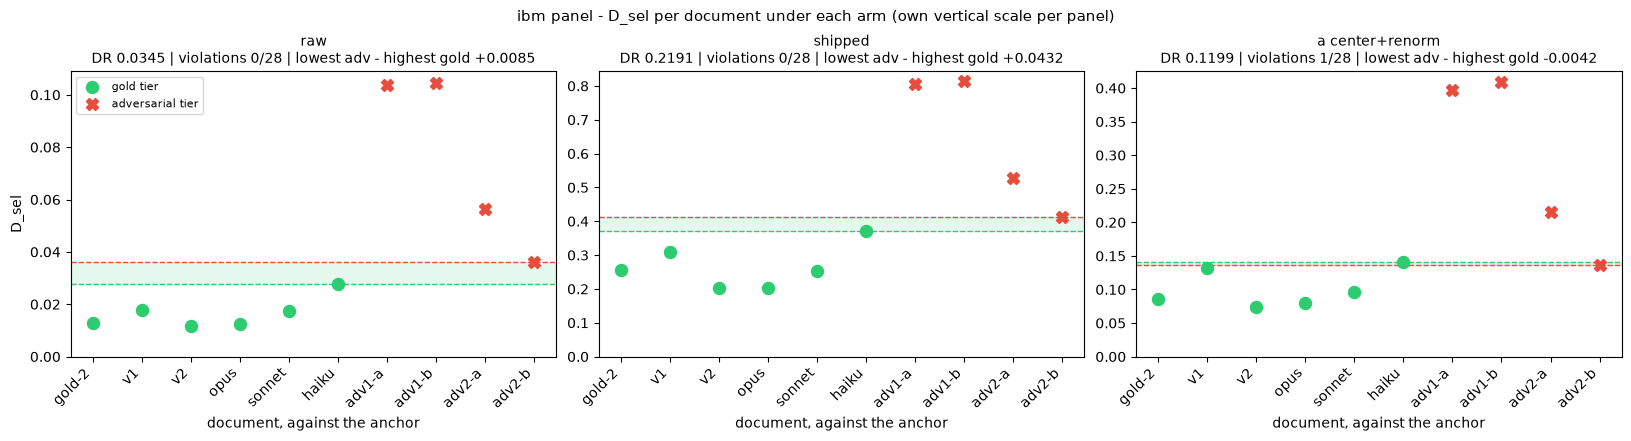

In [18]:
fig, axes = plt.subplots(1, len(ARMS_RUN), figsize=(5.4 * len(ARMS_RUN), 4.3), constrained_layout=True, squeeze=False)
x = np.arange(len(NONANCHOR))
for ax, arm in zip(axes[0], ARMS_RUN):
    p = PANEL[arm]
    for docs_t, marker, color, name in ((GOLD_NONANCHOR, "o", C_GOLD, "gold tier"), (adv_labels, "X", C_ADV, "adversarial tier")):
        ax.scatter([NONANCHOR.index(l) for l in docs_t], [p["d_sel"][l] for l in docs_t], marker=marker, s=75, color=color,
                   label=name, zorder=3)
    max_gold = max(p["d_sel"][l] for l in GOLD_NONANCHOR)
    min_adv = min(p["d_sel"][l] for l in adv_labels)
    ax.axhline(max_gold, color=C_GOLD, ls="--", lw=1)
    ax.axhline(min_adv, color=C_ADV, ls="--", lw=1)
    lo, hi = sorted((max_gold, min_adv))
    ax.axhspan(lo, hi, color=C_GOLD if p["sel_margin"] > 0 else C_ADV, alpha=0.12)
    ax.set_xticks(x)
    ax.set_xticklabels(NONANCHOR, rotation=45, ha="right")
    ax.set_ylim(bottom=0)
    ax.set_xlabel("document, against the anchor")
    ax.set_title(f"{arm}\nDR {p['DR']:.4f} | violations {v_text(p)} | lowest adv - highest gold {p['sel_margin']:+.4f}", fontsize=10)
axes[0][0].set_ylabel("D_sel")
axes[0][0].legend(fontsize=8, loc="upper left")
fig.suptitle("ibm panel - D_sel per document under each arm (own vertical scale per panel)", fontsize=11)
plt.show()

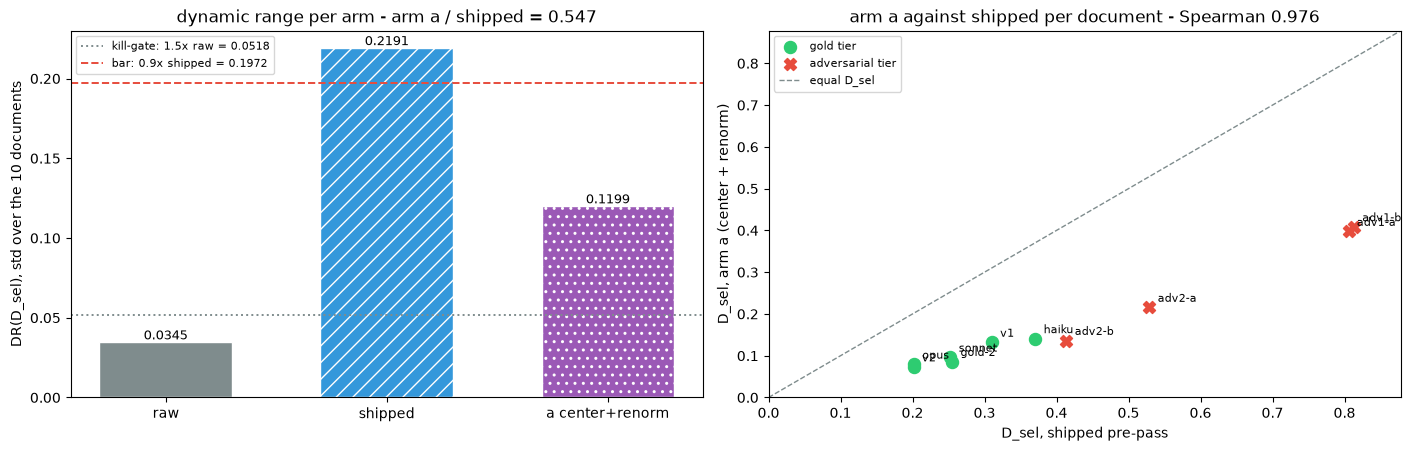

In [19]:
if PROCEED:
    fig, (ax_dr, ax_sc) = plt.subplots(1, 2, figsize=(14, 4.4), constrained_layout=True)
    for i, arm in enumerate(ARMS):
        bar = ax_dr.bar(i, PANEL[arm]["DR"], 0.6, color=ARM_COLOR[arm], hatch=ARM_HATCH[arm], edgecolor="white")
        ax_dr.bar_label(bar, fmt="%.4f", fontsize=9)
    ax_dr.axhline(GATE_MIN_DR_RATIO * DR_RAW, color=ARM_COLOR[RAW], ls=":", lw=1.4,
                  label=f"kill-gate: {GATE_MIN_DR_RATIO}x raw = {GATE_MIN_DR_RATIO * DR_RAW:.4f}")
    ax_dr.axhline(BAR_DR_RATIO * DR_SHIPPED, color=C_ADV, ls="--", lw=1.4,
                  label=f"bar: {BAR_DR_RATIO}x shipped = {BAR_DR_RATIO * DR_SHIPPED:.4f}")
    ax_dr.set_xticks(range(len(ARMS)))
    ax_dr.set_xticklabels(ARMS)
    ax_dr.set_ylabel("DR(D_sel), std over the 10 documents")
    ax_dr.set_title(f"dynamic range per arm - arm a / shipped = {DR_RATIO_A_SHIPPED:.3f}")
    ax_dr.legend(fontsize=8, loc="upper left")

    for docs_t, marker, color, name in ((GOLD_NONANCHOR, "o", C_GOLD, "gold tier"), (adv_labels, "X", C_ADV, "adversarial tier")):
        ax_sc.scatter([PANEL[SHIPPED]["d_sel"][l] for l in docs_t], [PANEL[ARM_A]["d_sel"][l] for l in docs_t],
                      marker=marker, s=75, color=color, label=name, zorder=3)
    for l in NONANCHOR:
        ax_sc.annotate(l, (PANEL[SHIPPED]["d_sel"][l], PANEL[ARM_A]["d_sel"][l]), textcoords="offset points",
                       xytext=(6, 4), fontsize=8)
    top = max(PANEL[SHIPPED]["d_sel"][l] for l in NONANCHOR) * 1.08
    ax_sc.plot([0, top], [0, top], color=ARM_COLOR[RAW], ls="--", lw=1, label="equal D_sel")
    ax_sc.set_xlim(0, top)
    ax_sc.set_ylim(0, top)
    ax_sc.set_xlabel("D_sel, shipped pre-pass")
    ax_sc.set_ylabel("D_sel, arm a (center + renorm)")
    ax_sc.set_title(f"arm a against shipped per document - Spearman {spearman_d_sel(PANEL[ARM_A], PANEL[SHIPPED]):.3f}")
    ax_sc.legend(fontsize=8, loc="upper left")
    plt.show()
else:
    console.print(NOT_RUN)

## Readings without a bar - rank agreement, contrast, distance to the source

Registered as reported without a bar: the Spearman rank correlation of `D_sel` between arm a and the shipped
arm over the 10 documents, the gold-to-adversarial contrast per arm (the E04 helper quoted above: mean
adversarial `D_sel` divided by mean non-anchor gold `D_sel`), and `closeness_a` and `residual_a` per arm. With
the registered argument order, `a` is the document, so both are the document's distance-to-source readings.
The anchor's own readings (`closeness_b`) are given as a range, because the per-triple pool changes them with
the partner document.

In [20]:
if PROCEED:
    SPEARMAN = {"arm_a_vs_shipped": spearman_d_sel(PANEL[ARM_A], PANEL[SHIPPED]),
                "raw_vs_shipped": spearman_d_sel(PANEL[RAW], PANEL[SHIPPED]),
                "arm_a_vs_raw": spearman_d_sel(PANEL[ARM_A], PANEL[RAW])}
    CONTRAST = {arm: PANEL[arm]["contrast"] for arm in ARMS}
    CLOSE_A = {arm: {l: PANEL[arm]["fields"][l]["closeness_a"] for l in NONANCHOR} for arm in ARMS}
    RESID_A = {arm: {l: PANEL[arm]["fields"][l]["residual_a"] for l in NONANCHOR} for arm in ARMS}
    CLOSE_B_RANGE = {arm: (min(PANEL[arm]["fields"][l]["closeness_b"] for l in NONANCHOR),
                           max(PANEL[arm]["fields"][l]["closeness_b"] for l in NONANCHOR)) for arm in ARMS}
    CLOSE_DIFF = {l: CLOSE_A[ARM_A][l] - CLOSE_A[SHIPPED][l] for l in NONANCHOR}
    CLOSE_DIFF_MAX_DOC = max(CLOSE_DIFF, key=lambda l: abs(CLOSE_DIFF[l]))
    CLIPPED = {arm: sum(RESID_A[arm][l] >= SMD_MAX for l in NONANCHOR) for arm in ARMS}

    CLOSE_TIER_GAP = {arm: tier_mean(CLOSE_A[arm], GOLD_NONANCHOR) - tier_mean(CLOSE_A[arm], adv_labels) for arm in ARMS}

    METRICS["no_bar"] = {
        "spearman_d_sel": SPEARMAN, "contrast": CONTRAST, "closeness_a": CLOSE_A, "residual_a": RESID_A,
        "closeness_b_anchor_range": {arm: list(v) for arm, v in CLOSE_B_RANGE.items()},
        "closeness_a_arm_a_minus_shipped": CLOSE_DIFF,
        "max_abs_closeness_a_diff_arm_a_vs_shipped": abs(CLOSE_DIFF[CLOSE_DIFF_MAX_DOC]),
        "max_abs_closeness_a_diff_at": CLOSE_DIFF_MAX_DOC,
        "closeness_a_gold_minus_adversarial_mean": CLOSE_TIER_GAP,
        "residual_a_at_or_above_sqrt2": CLIPPED,
    }
    KEY.update(spearman_d_sel_arm_a_vs_shipped=SPEARMAN["arm_a_vs_shipped"], spearman_d_sel_raw_vs_shipped=SPEARMAN["raw_vs_shipped"],
               contrast_raw=CONTRAST[RAW], contrast_shipped=CONTRAST[SHIPPED], contrast_arm_a=CONTRAST[ARM_A],
               max_abs_closeness_a_diff_arm_a_vs_shipped=abs(CLOSE_DIFF[CLOSE_DIFF_MAX_DOC]),
               max_abs_closeness_a_diff_arm_a_vs_shipped_pts=abs(CLOSE_DIFF[CLOSE_DIFF_MAX_DOC]) * 100.0,
               closeness_a_gold_minus_adversarial_mean_shipped=CLOSE_TIER_GAP[SHIPPED],
               closeness_a_gold_minus_adversarial_mean_arm_a=CLOSE_TIER_GAP[ARM_A])

    t = Table(title="distance to the source per document: closeness_a and residual_a per arm", header_style="bold medium_purple")
    for col in ("document", "tier", "closeness raw", "closeness shipped", "closeness arm a", "arm a - shipped",
                "residual raw", "residual shipped", "residual arm a"):
        t.add_column(col, justify="left" if col in ("document", "tier") else "right")
    for l in NONANCHOR:
        t.add_row(l, tier_cell(l), f"{CLOSE_A[RAW][l]:.4f}", f"{CLOSE_A[SHIPPED][l]:.4f}",
                  f"{CLOSE_A[ARM_A][l]:.4f}", f"{CLOSE_DIFF[l]:+.4f}", f"{RESID_A[RAW][l]:.4f}", f"{RESID_A[SHIPPED][l]:.4f}",
                  f"{RESID_A[ARM_A][l]:.4f}")
    c = Table(title="readings without a bar, per arm", header_style="bold medium_purple")
    for col in ("arm", "contrast (mean adversarial / mean gold D_sel)", "Spearman of D_sel with shipped",
                "mean closeness_a gold - adversarial", "anchor closeness_b, lowest to highest", "residual_a at or above sqrt(2)"):
        c.add_column(col, justify="left" if col == "arm" else "right")
    for arm, rho in ((RAW, SPEARMAN["raw_vs_shipped"]), (SHIPPED, 1.0), (ARM_A, SPEARMAN["arm_a_vs_shipped"])):
        c.add_row(arm, f"{CONTRAST[arm]:.4f}", f"{rho:.4f}", f"{CLOSE_TIER_GAP[arm]:+.4f}",
                  f"{CLOSE_B_RANGE[arm][0]:.4f} to {CLOSE_B_RANGE[arm][1]:.4f}", f"{CLIPPED[arm]}/{len(NONANCHOR)}")
    console.print(Group(t, c, Panel(
        f"Spearman of D_sel, arm a against shipped = [bold]{SPEARMAN['arm_a_vs_shipped']:.4f}[/bold] over {len(NONANCHOR)} documents "
        f"(raw against shipped {SPEARMAN['raw_vs_shipped']:.4f}, arm a against raw {SPEARMAN['arm_a_vs_raw']:.4f})\n"
        f"contrast: raw {CONTRAST[RAW]:.4f} | shipped {CONTRAST[SHIPPED]:.4f} | arm a {CONTRAST[ARM_A]:.4f}\n"
        f"largest |closeness_a difference|, arm a against shipped = {abs(CLOSE_DIFF[CLOSE_DIFF_MAX_DOC]):.6f} "
        f"({abs(CLOSE_DIFF[CLOSE_DIFF_MAX_DOC]) * 100:.2f} closeness points) at {CLOSE_DIFF_MAX_DOC}",
        border_style="steel_blue")))
else:
    console.print(NOT_RUN)

                                   distance to the source per document: closeness_a and residual_a per arm                                    
┏━━━━━━━━━━┳━━━━━━┳━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━┓
┃ document ┃ tier ┃ closeness raw ┃ closeness shipped ┃ closeness arm a ┃ arm a - shipped ┃ residual raw ┃ residual shipped ┃ residual arm a ┃
┡━━━━━━━━━━╇━━━━━━╇━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━┩
│ gold-2   │ gold │        0.5088 │            0.1454 │          0.1648 │         +0.0194 │       0.6946 │           1.2087 │         1.1812 │
│ v1       │ gold │        0.5008 │            0.1374 │          0.1598 │         +0.0225 │       0.7059 │           1.2199 │         1.1882 │
│ v2       │ gold │        0.5030 │            0.1278 │          0.1545 │         +0.0266 │       0.7029 │           1.2334 │         1.1958 │
│ opus     │ gold │        0.5012 │            0.1218 │          0.1560 │         +0.0342 │       0.7053 │           1.2420 │         1.1936 │
│ sonnet   │ gold │        0.4985 │            0.1179 │          0.1505 │         +0.0326 │       0.7092 │           1.2475 │         1.2013 │
│ haiku    │ gold │        0.5072 │            0.1304 │          0.1550 │         +0.0246 │       0.6970 │           1.2298 │         1.1950 │
│ adv1-a   │ adv1 │        0.4573 │            0.0410 │          0.0997 │         +0.0587 │       0.7675 │           1.3562 │         1.2732 │
│ adv1-b   │ adv1 │        0.4527 │            0.0417 │          0.0948 │         +0.0531 │       0.7740 │           1.3552 │         1.2801 │
│ adv2-a   │ adv2 │        0.4603 │            0.0000 │          0.1002 │         +0.1002 │       0.7632 │           1.4150 │         1.2725 │
│ adv2-b   │ adv2 │        0.4668 │            0.0388 │          0.1113 │         +0.0726 │       0.7541 │           1.3594 │         1.2568 │
└──────────┴──────┴───────────────┴───────────────────┴─────────────────┴─────────────────┴──────────────┴──────────────────┴────────────────┘
                                                           readings without a bar, per arm                                                            
┏━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃                 ┃          contrast (mean ┃                         ┃                         ┃                          ┃                         ┃
┃                 ┃ adversarial / mean gold ┃  Spearman of D_sel with ┃ mean closeness_a gold - ┃      anchor closeness_b, ┃  residual_a at or above ┃
┃ arm             ┃                  D_sel) ┃                 shipped ┃             adversarial ┃        lowest to highest ┃                 sqrt(2) ┃
┡━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━┩
│ raw             │                  4.5066 │                  0.9879 │                 +0.0440 │         0.5028 to 0.5028 │                    0/10 │
│ shipped         │                  2.4134 │                  1.0000 │                 +0.0997 │         0.1266 to 0.1310 │                    1/10 │
│ a center+renorm │                  2.8565 │                  0.9758 │                 +0.0553 │         0.1520 to 0.1729 │                    0/10 │
└─────────────────┴─────────────────────────┴─────────────────────────┴─────────────────────────┴──────────────────────────┴─────────────────────────┘
╭────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────╮
│ Spearman of D_sel, arm a against shipped = 0.9758 over 10 documents (raw against shipped 0.9879, arm a against raw 0.9879)                         │
│ contrast: raw 4.5066 | shipped 2.4134 | a

## Readings without a bar - pool geometry and the coverage assignment

The hypothesis names a mechanism: the per-triple pool is dominated by the source, the first principal
component of the centered pool is nearly orthogonal to the mean direction, and projecting it out changes which
source statement each summary statement is nearest to. Four readings test that chain. None has a bar.

- **Pool geometry per triple** - pool size, source share, `cos(centered PC1, mean direction)`, the share of the centered variance on PC1, and the share of the PC1 energy carried by the source statements
- **Nearest source statement** - per document statement, the source statement with the highest coverage assignment, compared between arms
- **Assignment sharpness** - the mean entropy of a statement's assignment over the 70 source statements (0 = one source statement, `ln 70` = 4.248 = uniform) and the mean highest assignment
- **Ground cost** - the mean cost `sqrt(2 - 2cos)` between two different source statements, the scale `D_sel` is transported on

In [21]:
if PROCEED:
    GEO = {l: pool_geometry(ibm_triple(l, S)) for l in NONANCHOR}
    COV = {arm: {l: coverage_readings(arm_arrays(ibm_triple(l, S), arm)) for l in NONANCHOR} for arm in ARMS}
    N_DOC_STATEMENTS = sum(len(emb[l]) for l in NONANCHOR)

    AGREE = {"arm_a_vs_shipped": nearest_agreement(COV[ARM_A], COV[SHIPPED]),
             "raw_vs_shipped": nearest_agreement(COV[RAW], COV[SHIPPED]),
             "arm_a_vs_raw": nearest_agreement(COV[ARM_A], COV[RAW])}
    SHARP = {arm: dict(mean_row_entropy=float(np.mean([COV[arm][l]["mean_row_entropy"] for l in NONANCHOR])),
                       mean_row_max=float(np.mean([COV[arm][l]["mean_row_max"] for l in NONANCHOR])),
                       mean_source_cost=float(np.mean([COV[arm][l]["mean_source_cost"] for l in NONANCHOR])))
             for arm in ARMS}
    GEO_RANGE = {k: (min(g[k] for g in GEO.values()), max(g[k] for g in GEO.values()))
                 for k in ("n_pool", "source_share", "mean_norm", "cos_centered_pc1_mean", "pc1_variance_share", "pc1_energy_source_share")}

    METRICS["mechanism"] = {
        "pool_geometry_by_doc": GEO, "pool_geometry_range": {k: list(v) for k, v in GEO_RANGE.items()},
        "nearest_source_same": AGREE, "document_statements": N_DOC_STATEMENTS,
        "nearest_source_same_share": {k: v / N_DOC_STATEMENTS for k, v in AGREE.items()},
        "assignment_and_cost_by_arm": SHARP, "uniform_entropy": float(np.log(len(S))),
    }
    KEY.update(cos_centered_pc1_mean_min=GEO_RANGE["cos_centered_pc1_mean"][0], cos_centered_pc1_mean_max=GEO_RANGE["cos_centered_pc1_mean"][1],
               pc1_variance_share_min=GEO_RANGE["pc1_variance_share"][0], pc1_variance_share_max=GEO_RANGE["pc1_variance_share"][1],
               pc1_energy_source_share_min=GEO_RANGE["pc1_energy_source_share"][0],
               pc1_energy_source_share_max=GEO_RANGE["pc1_energy_source_share"][1],
               nearest_source_same_arm_a_vs_shipped=AGREE["arm_a_vs_shipped"], nearest_source_same_raw_vs_shipped=AGREE["raw_vs_shipped"],
               nearest_source_same_arm_a_vs_raw=AGREE["arm_a_vs_raw"], document_statements=N_DOC_STATEMENTS,
               mean_row_entropy_raw=SHARP[RAW]["mean_row_entropy"], mean_row_entropy_shipped=SHARP[SHIPPED]["mean_row_entropy"],
               mean_row_entropy_arm_a=SHARP[ARM_A]["mean_row_entropy"],
               mean_source_cost_raw=SHARP[RAW]["mean_source_cost"], mean_source_cost_shipped=SHARP[SHIPPED]["mean_source_cost"],
               mean_source_cost_arm_a=SHARP[ARM_A]["mean_source_cost"])

    g = Table(title="pool geometry per triple {document, anchor, source}", header_style="bold medium_purple")
    for col in ("document", "pool", "source share", "pooled mean norm", "cos(centered PC1, mean)", "PC1 share of centered variance",
                "source share of PC1 energy"):
        g.add_column(col, justify="left" if col == "document" else "right")
    for l in NONANCHOR:
        r = GEO[l]
        g.add_row(l, str(r["n_pool"]), f"{r['source_share']:.3f}", f"{r['mean_norm']:.4f}", f"{r['cos_centered_pc1_mean']:.4f}",
                  f"{r['pc1_variance_share']:.4f}", f"{r['pc1_energy_source_share']:.4f}")
    a = Table(title="coverage assignment and ground cost per arm (mean over the 10 triples)", header_style="bold medium_purple")
    for col in ("arm", "mean assignment entropy (nats)", "mean highest assignment", "mean source-to-source cost",
                "nearest source equal to shipped"):
        a.add_column(col, justify="left" if col == "arm" else "right")
    for arm, same in ((RAW, AGREE["raw_vs_shipped"]), (SHIPPED, N_DOC_STATEMENTS), (ARM_A, AGREE["arm_a_vs_shipped"])):
        a.add_row(arm, f"{SHARP[arm]['mean_row_entropy']:.4f}", f"{SHARP[arm]['mean_row_max']:.4f}",
                  f"{SHARP[arm]['mean_source_cost']:.4f}", f"{same}/{N_DOC_STATEMENTS}")
    console.print(Group(g, a, Panel(
        f"pool {GEO_RANGE['n_pool'][0]} to {GEO_RANGE['n_pool'][1]} statements, source share "
        f"{GEO_RANGE['source_share'][0]:.3f} to {GEO_RANGE['source_share'][1]:.3f} | cos(centered PC1, mean direction) "
        f"{GEO_RANGE['cos_centered_pc1_mean'][0]:.4f} to {GEO_RANGE['cos_centered_pc1_mean'][1]:.4f} (the record cites "
        f"{RECORD_COS_CENTERED_PC1_MEAN} from the 76-statement symmetric pool of E14-H75)\n"
        f"PC1 share of the centered variance {GEO_RANGE['pc1_variance_share'][0]:.4f} to {GEO_RANGE['pc1_variance_share'][1]:.4f} | "
        f"source share of the PC1 energy {GEO_RANGE['pc1_energy_source_share'][0]:.4f} to {GEO_RANGE['pc1_energy_source_share'][1]:.4f}\n"
        f"nearest source statement equal under arm a and shipped: [bold]{AGREE['arm_a_vs_shipped']}/{N_DOC_STATEMENTS}[/bold] document "
        f"statements | raw and shipped {AGREE['raw_vs_shipped']}/{N_DOC_STATEMENTS} | arm a and raw {AGREE['arm_a_vs_raw']}/{N_DOC_STATEMENTS}\n"
        f"uniform assignment entropy ln {len(S)} = {np.log(len(S)):.4f}",
        border_style="steel_blue")))
else:
    console.print(NOT_RUN)

                                             pool geometry per triple {document, anchor, source}                                             
┏━━━━━━━━━━┳━━━━━━┳━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ document ┃ pool ┃ source share ┃ pooled mean norm ┃ cos(centered PC1, mean) ┃ PC1 share of centered variance ┃ source share of PC1 energy ┃
┡━━━━━━━━━━╇━━━━━━╇━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│ gold-2   │   92 │        0.761 │           0.7878 │                  0.3054 │                         0.6858 │                     0.8846 │
│ v1       │   91 │        0.769 │           0.7857 │                  0.3003 │                         0.6841 │                     0.8864 │
│ v2       │   91 │        0.769 │           0.7867 │                  0.3013 │                         0.6867 │                     0.8864 │
│ opus     │   91 │        0.769 │           0.7860 │                  0.3001 │                         0.6848 │                     0.8863 │
│ sonnet   │   89 │        0.787 │           0.7842 │                  0.2927 │                         0.6896 │                     0.8893 │
│ haiku    │   93 │        0.753 │           0.7894 │                  0.3091 │                         0.6835 │                     0.8856 │
│ adv1-a   │   88 │        0.795 │           0.7807 │                  0.2859 │                         0.6840 │                     0.8919 │
│ adv1-b   │   89 │        0.787 │           0.7812 │                  0.2908 │                         0.6837 │                     0.8866 │
│ adv2-a   │   81 │        0.864 │           0.7748 │                  0.2499 │                         0.6920 │                     0.9200 │
│ adv2-b   │   83 │        0.843 │           0.7769 │                  0.2618 │                         0.6921 │                     0.9093 │
└──────────┴──────┴──────────────┴──────────────────┴─────────────────────────┴────────────────────────────────┴────────────────────────────┘
                                   coverage assignment and ground cost per arm (mean over the 10 triples)                                    
┏━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ arm             ┃ mean assignment entropy (nats) ┃ mean highest assignment ┃ mean source-to-source cost ┃ nearest source equal to shipped ┃
┡━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│ raw             │                         3.3965 │                  0.0959 │                     0.8375 │                           51/88 │
│ shipped         │                         3.0866 │                  0.2747 │                     1.3807 │                           88/88 │
│ a center+renorm │                         2.8259 │                  0.2276 │                     1.3251 │                           60/88 │
└─────────────────┴────────────────────────────────┴─────────────────────────┴────────────────────────────┴─────────────────────────────────┘
╭────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────╮
│ pool 81 to 93 statements, source share 0.753 to 0.864 | cos(centered PC1, mean direction) 0.2499 to 0.3091 (the record cites 0.056 from the        │
│ 76-statement symmetric pool of E14-H75)                                                                                                            │
│ PC1 share of the centered variance 0.6835 to 0.6921 | source share of the PC1 energy 0.8846 to 0.9200                                              │
│ nearest source statement equal under arm a and shipped: 60/88 document statements | raw and shipped 51/88 | arm a and raw 79/88 

## Readings without a bar - what the first principal component separates

The pool geometry above reads a first principal component that carries most of the centered variance of every
triple. This section reads what that component separates. The shipped reader segments with `markdown=False`,
so the markup lines of the source reach the segmenter as text. Four readings, none with a bar and none in the
registered record. The section was added after the first execution of this notebook, and its word rules were
chosen with those outputs in view (configuration cell).

- **Inventory** - the source statements by word count, and the one-word statements by text
- **PC1 coordinate by group** - per triple, the coordinate on the centered PC1 of the document statements, the source statements of two words or more and the one-word source statements; the sign is fixed so that the document statements average negative
- **Counterfactual** - the three arms scored again with short statements removed from the source, under two rules: fewer than 2 words, and fewer than 5 words. The embeddings of the remaining statements are the same arrays, not re-encoded
- **Ground cost between source statements of two words or more** - the mean cost `sqrt(2 - 2cos)` between two of those statements per arm, in the registered pool and in the counterfactual pools: `D_sel` is transported between these statements

In [22]:
if PROCEED:
    source_words = np.array([len(t.split()) for t in source_texts])
    ONE_WORD = source_words < FRAGMENT_MIN_WORDS                       # mask over the 70 source statements
    N_ONE_WORD = int(ONE_WORD.sum())
    ONE_WORD_TEXTS = Counter(t for t, m in zip(source_texts, ONE_WORD) if m)
    N_DISTINCT_SOURCE = len(set(source_texts))
    DOC_ONE_WORD = int(sum(len(t.split()) < FRAGMENT_MIN_WORDS for l in labels for t in texts[l]))
    WERG_ONE_WORD = int(sum(len(t.split()) < FRAGMENT_MIN_WORDS for t in werg_source_texts))

    PC1G = {l: pc1_groups(ibm_triple(l, S), ONE_WORD) for l in NONANCHOR}
    PC1G_RANGE = {g: (min(PC1G[l][g][0] for l in NONANCHOR), max(PC1G[l][g][1] for l in NONANCHOR))
                  for g in ("documents", "source_two_words_or_more", "source_one_word")}

    CF = {k: counterfactual(k, source_words) for k in COUNTERFACTUAL_MIN_WORDS}
    CF_RAW_UNCHANGED = raw_unchanged()
    PROSE_COST = {arm: mean_source_cost(S, ~ONE_WORD, arm) for arm in ARMS}        # registered pool, statements of 2 words or more
    CF1, CF5 = CF[COUNTERFACTUAL_MIN_WORDS[0]], CF[COUNTERFACTUAL_MIN_WORDS[1]]

    METRICS["pc1_reading"] = {
        "added_after_first_execution": True, "word_rules": list(COUNTERFACTUAL_MIN_WORDS),
        "source_statements": len(S), "source_one_word_statements": N_ONE_WORD,
        "source_one_word_texts": dict(ONE_WORD_TEXTS), "source_distinct_texts": N_DISTINCT_SOURCE,
        "source_words_median": float(np.median(source_words)), "source_words_max": int(source_words.max()),
        "summary_one_word_statements": DOC_ONE_WORD, "wergeland_source_one_word_statements": WERG_ONE_WORD,
        "pc1_coordinate_by_group_by_doc": PC1G, "pc1_coordinate_by_group_range": {g: list(v) for g, v in PC1G_RANGE.items()},
        "counterfactual_by_min_words": {str(k): v for k, v in CF.items()},
        "counterfactual_raw_embeddings_byte_identical": CF_RAW_UNCHANGED,
        "mean_source_cost": {"all_statements_registered_pool": {arm: SHARP[arm]["mean_source_cost"] for arm in ARMS},
                             "two_words_or_more_registered_pool": PROSE_COST},
    }
    KEY.update(source_one_word_statements=N_ONE_WORD, source_distinct_texts=N_DISTINCT_SOURCE,
               pc1_coord_documents_min=PC1G_RANGE["documents"][0], pc1_coord_documents_max=PC1G_RANGE["documents"][1],
               pc1_coord_source_one_word_min=PC1G_RANGE["source_one_word"][0],
               pc1_coord_source_one_word_max=PC1G_RANGE["source_one_word"][1],
               pc1_coord_source_other_min=PC1G_RANGE["source_two_words_or_more"][0],
               pc1_coord_source_other_max=PC1G_RANGE["source_two_words_or_more"][1],
               source_cost_two_words_or_more_raw=PROSE_COST[RAW], source_cost_two_words_or_more_shipped=PROSE_COST[SHIPPED],
               source_cost_two_words_or_more_arm_a=PROSE_COST[ARM_A])
    for tag, c in (("counterfactual", CF1), ("counterfactual_5_words", CF5)):
        KEY.update({
            f"{tag}_source_statements": c["source_statements"],
            f"{tag}_dr_raw": c["arms"][RAW]["DR"], f"{tag}_dr_shipped": c["arms"][SHIPPED]["DR"], f"{tag}_dr_arm_a": c["arms"][ARM_A]["DR"],
            f"{tag}_dr_ratio_shipped_over_raw": c["dr_ratio_shipped_over_raw"],
            f"{tag}_dr_ratio_arm_a_over_shipped": c["dr_ratio_arm_a_over_shipped"],
            f"{tag}_violations_raw": c["arms"][RAW]["V"], f"{tag}_violations_shipped": c["arms"][SHIPPED]["V"],
            f"{tag}_violations_arm_a": c["arms"][ARM_A]["V"],
            f"{tag}_sel_margin_shipped": c["arms"][SHIPPED]["sel_margin"], f"{tag}_sel_margin_arm_a": c["arms"][ARM_A]["sel_margin"],
            f"{tag}_spearman_d_sel_arm_a_vs_shipped": c["spearman_d_sel_arm_a_vs_shipped"],
            f"{tag}_pc1_variance_share_min": c["pc1_variance_share_range"][0],
            f"{tag}_pc1_variance_share_max": c["pc1_variance_share_range"][1],
            f"{tag}_source_cost_shipped": c["mean_source_cost"][SHIPPED], f"{tag}_source_cost_arm_a": c["mean_source_cost"][ARM_A],
        })

    inv = Table(title=f"ibm source - {len(S)} statements through the shipped reader", header_style="bold medium_purple")
    for col in ("group", "statements", "texts (count)"):
        inv.add_column(col, justify="right" if col == "statements" else "left")
    inv.add_row(f"fewer than {FRAGMENT_MIN_WORDS} words", str(N_ONE_WORD),
                escape(" | ".join(f"{t!r} ({n})" for t, n in ONE_WORD_TEXTS.most_common())))
    inv.add_row(f"{FRAGMENT_MIN_WORDS} words or more", str(len(S) - N_ONE_WORD),
                f"median {np.median(source_words[~ONE_WORD]):.0f} words, longest {source_words.max()} words, "
                f"{int(((source_words >= FRAGMENT_MIN_WORDS) & (source_words < COUNTERFACTUAL_MIN_WORDS[1])).sum())} of them with fewer than "
                f"{COUNTERFACTUAL_MIN_WORDS[1]} words")
    grp = Table(title="signed coordinate on the centered PC1, lowest to highest over the 10 triples", header_style="bold medium_purple")
    for col in ("statement group", "lowest", "highest"):
        grp.add_column(col, justify="left" if col == "statement group" else "right")
    for g, name in (("documents", "document and anchor statements"), ("source_two_words_or_more", f"source, {FRAGMENT_MIN_WORDS} words or more"),
                    ("source_one_word", "source, one word")):
        grp.add_row(name, f"{PC1G_RANGE[g][0]:+.3f}", f"{PC1G_RANGE[g][1]:+.3f}")
    cf = Table(title="counterfactual - short statements removed from the source, same embeddings", header_style="bold medium_purple")
    for col in ("source", "statements", "arm", "DR(D_sel)", "DR / raw", "DR / shipped", "violations",
                "lowest adversarial - highest gold", "contrast", "PC1 share of centered variance"):
        cf.add_column(col, justify="left" if col in ("source", "arm") else "right")
    for arm in ARMS:
        p = PANEL[arm]
        cf.add_row("registered", str(len(S)), arm, f"{p['DR']:.6f}", f"{p['DR'] / DR_RAW:.4f}", f"{p['DR'] / DR_SHIPPED:.4f}", v_text(p),
                   f"{p['sel_margin']:+.6f}", f"{p['contrast']:.4f}",
                   f"{GEO_RANGE['pc1_variance_share'][0]:.4f} to {GEO_RANGE['pc1_variance_share'][1]:.4f}")
    for k, c in CF.items():
        for arm in ARMS:
            a = c["arms"][arm]
            cf.add_row(f"fewer than {k} words removed", str(c["source_statements"]), arm, f"{a['DR']:.6f}",
                       f"{a['DR'] / c['arms'][RAW]['DR']:.4f}", f"{a['DR'] / c['arms'][SHIPPED]['DR']:.4f}", v_text(a),
                       f"{a['sel_margin']:+.6f}", f"{a['contrast']:.4f}",
                       f"{c['pc1_variance_share_range'][0]:.4f} to {c['pc1_variance_share_range'][1]:.4f}")
    gc = Table(title="mean ground cost between two source statements (mean over the 10 triples)", header_style="bold medium_purple")
    for col in ("arm", f"all {len(S)} statements, registered pool", f"the {len(S) - N_ONE_WORD} of {FRAGMENT_MIN_WORDS} words or more, registered pool",
                *[f"pool with fewer than {k} words removed ({c['source_statements']} statements)" for k, c in CF.items()]):
        gc.add_column(col, justify="left" if col == "arm" else "right")
    for arm in ARMS:
        gc.add_row(arm, f"{SHARP[arm]['mean_source_cost']:.4f}", f"{PROSE_COST[arm]:.4f}",
                   *[f"{c['mean_source_cost'][arm]:.4f}" for c in CF.values()])
    console.print(Group(inv, grp, cf, gc, Panel(
        f"source statements: {len(S)}, distinct texts {N_DISTINCT_SOURCE}, one-word statements [bold]{N_ONE_WORD}[/bold] | one-word "
        f"statements in the 11 summaries: {DOC_ONE_WORD} | in the Wergeland source: {WERG_ONE_WORD} of {len(S_W)}\n"
        + "\n".join(
            f"fewer than {k} words removed ({c['removed']} statements, {c['source_statements']} left): DR shipped / raw = "
            f"{c['dr_ratio_shipped_over_raw']:.4f} | DR arm a / shipped = [bold]{c['dr_ratio_arm_a_over_shipped']:.4f}[/bold] | violations "
            f"arm a {v_text(c['arms'][ARM_A])} | per-document D_sel arm a / shipped {c['d_sel_ratio_arm_a_over_shipped_range'][0]:.3f} to "
            f"{c['d_sel_ratio_arm_a_over_shipped_range'][1]:.3f} | Spearman arm a against shipped {c['spearman_d_sel_arm_a_vs_shipped']:.4f} | "
            f"shipped against the registered shipped arm {c['spearman_d_sel_shipped_vs_registered_shipped']:.4f} | cos(centered PC1, mean "
            f"direction) {c['cos_centered_pc1_mean_range'][0]:.4f} to {c['cos_centered_pc1_mean_range'][1]:.4f}"
            for k, c in CF.items())
        + f"\nregistered source: DR shipped / raw = {DR_RATIO_SHIPPED_RAW:.4f} | DR arm a / shipped = {DR_RATIO_A_SHIPPED:.4f} | violations "
        f"arm a {v_text(PANEL[ARM_A])} | raw embeddings byte-identical after the counterfactuals: {CF_RAW_UNCHANGED}",
        border_style="steel_blue")))
else:
    console.print(NOT_RUN)

                          ibm source - 70 statements through the shipped reader                           
┏━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ group              ┃ statements ┃ texts (count)                                                        ┃
┡━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│ fewer than 2 words │         22 │ '-' (13) | '###' (6) | '##' (2) | 'Overview' (1)                     │
│ 2 words or more    │         48 │ median 24 words, longest 70 words, 6 of them with fewer than 5 words │
└────────────────────┴────────────┴──────────────────────────────────────────────────────────────────────┘
  signed coordinate on the centered PC1, lowest to   
             highest over the 10 triples             
┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━┳━━━━━━━━━┓
┃ statement group                ┃ lowest ┃ highest ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━╇━━━━━━━━━┩
│ document and anchor statements │ -0.443 │  -0.230 │
│ source, 2 words or more        │ -0.434 │  +0.521 │
│ source, one word               │ +0.709 │  +0.868 │
└────────────────────────────────┴────────┴─────────┘
                                      counterfactual - short statements removed from the source, same embeddings                                      
┏━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━┳━━━━━━━━━━┳━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃                  ┃            ┃                 ┃           ┃          ┃              ┃            ┃           lowest ┃          ┃    PC1 share of ┃
┃                  ┃            ┃                 ┃           ┃          ┃              ┃            ┃    adversarial - ┃          ┃        centered ┃
┃ source           ┃ statements ┃ arm             ┃ DR(D_sel) ┃ DR / raw ┃ DR / shipped ┃ violations ┃     highest gold ┃ contrast ┃        variance ┃
┡━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━╇━━━━━━━━━━╇━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ registered       │         70 │ raw             │  0.034535 │   1.0000 │       0.1576 │       0/28 │        +0.008483 │   4.5066 │       0.6835 to │
│                  │            │                 │           │          │              │            │                  │          │          0.6921 │
│ registered       │         70 │ shipped         │  0.219067 │   6.3433 │       1.0000 │       0/28 │        +0.043215 │   2.4134 │       0.6835 to │
│                  │            │                 │           │          │              │            │                  │          │          0.6921 │
│ registered       │         70 │ a center+renorm │  0.119861 │   3.4707 │       0.5471 │       1/28 │        -0.004160 │   2.8565 │       0.6835 to │
│                  │            │                 │           │          │              │            │                  │          │          0.6921 │
│ fewer than 2     │         48 │ raw             │  0.034541 │   1.0000 │       0.1318 │       0/28 │        +0.008458 │   4.5086 │       0.2980 to │
│ words removed    │            │                 │           │          │              │            │                  │          │          0.3211 │
│ fewer than 2     │         48 │ shipped         │  0.262116 │   7.5885 │       1.0000 │       0/28 │        +0.114406 │   2.6722 │       0.2980 to │
│ words removed    │            │                 │           │          │              │            │                  │          │          0.3211 │
│ fewer than 2     │         48 │ a center+renorm │  0.240237 │   6.9551 │       0.9165 │       0/28 │        +0.037854 │   2.6051 │       0.2980 to │
│ words removed    │            │                 │           │          │              │            │                  │          │          0.3211 │
│ fewer than 5     │         42 │ raw          

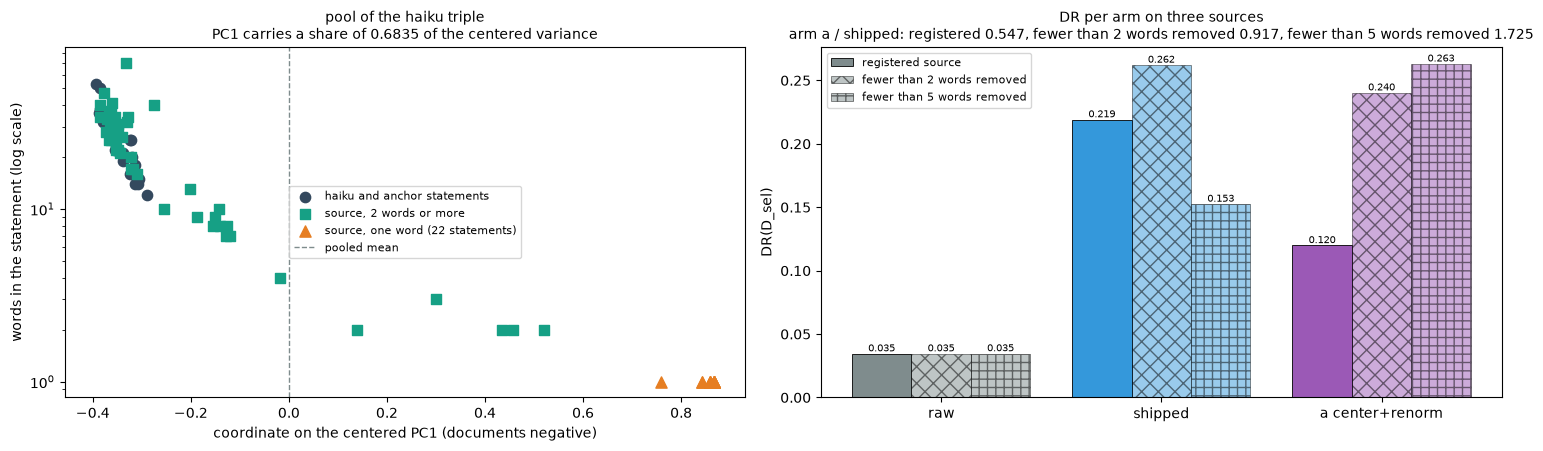

In [23]:
if PROCEED:
    FIG_DOC = "haiku"                                          # the gold document of the violating ordering under arm a
    coord = signed_pc1_coord(ibm_triple(FIG_DOC, S))
    n_doc = len(emb[FIG_DOC]) + len(emb[ANCHOR])
    doc_words = np.array([len(t.split()) for t in texts[FIG_DOC] + texts[ANCHOR]])
    fig, (ax_p, ax_d) = plt.subplots(1, 2, figsize=(15, 4.4), constrained_layout=True)
    ax_p.scatter(coord[:n_doc], doc_words, marker="o", s=55, color=C_DOC_STMT, label=f"{FIG_DOC} and anchor statements", zorder=3)
    ax_p.scatter(coord[n_doc:][~ONE_WORD], source_words[~ONE_WORD], marker="s", s=45, color=C_SRC_STMT,
                 label=f"source, {FRAGMENT_MIN_WORDS} words or more", zorder=3)
    ax_p.scatter(coord[n_doc:][ONE_WORD], source_words[ONE_WORD], marker="^", s=65, color=C_ONE_WORD,
                 label=f"source, one word ({N_ONE_WORD} statements)", zorder=3)
    ax_p.axvline(0, color=ARM_COLOR[RAW], ls="--", lw=1, label="pooled mean")
    ax_p.set_yscale("log")
    ax_p.set_xlabel("coordinate on the centered PC1 (documents negative)")
    ax_p.set_ylabel("words in the statement (log scale)")
    ax_p.set_title(f"pool of the {FIG_DOC} triple\nPC1 carries a share of {GEO[FIG_DOC]['pc1_variance_share']:.4f} of the centered variance",
                   fontsize=10)
    ax_p.legend(fontsize=8, loc="center")

    x, w = np.arange(len(ARMS)), 0.27
    sources = [("registered source", {arm: PANEL[arm]["DR"] for arm in ARMS}, "", 1.0)] + [
        (f"fewer than {k} words removed", {arm: c["arms"][arm]["DR"] for arm in ARMS}, hatch, 0.5)
        for (k, c), hatch in zip(CF.items(), ("xx", "++"))]
    for i, (name, dr, hatch, alpha) in enumerate(sources):
        bars = ax_d.bar(x + (i - 1) * w, [dr[arm] for arm in ARMS], w, color=[ARM_COLOR[arm] for arm in ARMS], edgecolor="black",
                        linewidth=0.6, alpha=alpha, hatch=hatch, label=name)
        ax_d.bar_label(bars, fmt="%.3f", fontsize=7)
    ax_d.set_xticks(x)
    ax_d.set_xticklabels(ARMS)
    ax_d.set_ylabel("DR(D_sel)")
    ax_d.set_title(f"DR per arm on three sources\narm a / shipped: registered {DR_RATIO_A_SHIPPED:.3f}, "
                   + ", ".join(f"fewer than {k} words removed {c['dr_ratio_arm_a_over_shipped']:.3f}" for k, c in CF.items()), fontsize=10)
    ax_d.legend(fontsize=8, loc="upper left")
    plt.show()
else:
    console.print(NOT_RUN)

## Readings without a bar - the Wergeland source and the E04 pool

Two more readings, neither with a bar.

- **Wergeland source** - the same three arms with the Wergeland article as the source and its three sections as the documents: three triples `{section, section, source}`. The fixture has no tiers, so only `D_sel`, its ratio between arms and the order of the three triples are read
- **E04 pool** - the three arms with the pre-pass estimated once from the pool of all 11 ibm summaries plus the source, the route E04-H15 scored. This shows how much of the reading belongs to the per-triple pool

In [24]:
if PROCEED:
    WERG = {arm: {f"{a}|{b}": fields(conditioned({"a": emb_w[a], "b": emb_w[b], "s": S_W}, arm)) for a, b in WERG_PAIRS}
            for arm in ARMS}
    WERG_RAW_UNCHANGED = raw_unchanged()
    WERG_KEYS = list(WERG[RAW])
    WERG_RATIO = {k: WERG[ARM_A][k]["d_sel"] / WERG[SHIPPED][k]["d_sel"] for k in WERG_KEYS}
    WERG_ORDER = {arm: sorted(WERG_KEYS, key=lambda k: WERG[arm][k]["d_sel"]) for arm in ARMS}
    WERG_DR = {arm: float(np.std([WERG[arm][k]["d_sel"] for k in WERG_KEYS])) for arm in ARMS}
    WERG_POOL_N = {f"{a}|{b}": len(emb_w[a]) + len(emb_w[b]) + len(S_W) for a, b in WERG_PAIRS}
    WERG_GEO = {f"{a}|{b}": pool_geometry({"a": emb_w[a], "b": emb_w[b], "s": S_W}) for a, b in WERG_PAIRS}

    E04_POOL = {arm: e04_pool_panel(arm) for arm in ARMS}
    E04_POOL_N = int(sum(len(emb[l]) for l in labels) + len(S))

    METRICS["wergeland"] = {
        "triples": WERG, "pool_statements": WERG_POOL_N, "source_statements": len(S_W),
        "d_sel_ratio_arm_a_over_shipped": WERG_RATIO, "order_by_d_sel": WERG_ORDER,
        "order_arm_a_equals_shipped": WERG_ORDER[ARM_A] == WERG_ORDER[SHIPPED],
        "dr_over_three_triples": WERG_DR, "dr_ratio_arm_a_over_shipped": WERG_DR[ARM_A] / WERG_DR[SHIPPED],
        "dr_ratio_shipped_over_raw": WERG_DR[SHIPPED] / WERG_DR[RAW], "pool_geometry": WERG_GEO,
        "raw_embeddings_byte_identical": WERG_RAW_UNCHANGED,
    }
    METRICS["e04_pool"] = {
        "pool_statements": E04_POOL_N, "arms": E04_POOL,
        "dr_ratio_shipped_over_raw": E04_POOL[SHIPPED]["DR"] / E04_POOL[RAW]["DR"],
        "dr_ratio_arm_a_over_shipped": E04_POOL[ARM_A]["DR"] / E04_POOL[SHIPPED]["DR"],
        "spearman_d_sel_arm_a_vs_shipped": spearman_d_sel(E04_POOL[ARM_A], E04_POOL[SHIPPED]),
    }
    KEY.update(wergeland_d_sel_ratio_arm_a_over_shipped_min=min(WERG_RATIO.values()),
               wergeland_d_sel_ratio_arm_a_over_shipped_max=max(WERG_RATIO.values()),
               wergeland_order_arm_a_equals_shipped=WERG_ORDER[ARM_A] == WERG_ORDER[SHIPPED],
               wergeland_dr_ratio_arm_a_over_shipped=WERG_DR[ARM_A] / WERG_DR[SHIPPED],
               wergeland_source_statements=len(S_W),
               wergeland_pc1_variance_share_min=min(g["pc1_variance_share"] for g in WERG_GEO.values()),
               wergeland_pc1_variance_share_max=max(g["pc1_variance_share"] for g in WERG_GEO.values()),
               e04_pool_dr_raw=E04_POOL[RAW]["DR"], e04_pool_dr_shipped=E04_POOL[SHIPPED]["DR"], e04_pool_dr_arm_a=E04_POOL[ARM_A]["DR"],
               e04_pool_dr_ratio_shipped_over_raw=E04_POOL[SHIPPED]["DR"] / E04_POOL[RAW]["DR"],
               e04_pool_dr_ratio_arm_a_over_shipped=E04_POOL[ARM_A]["DR"] / E04_POOL[SHIPPED]["DR"],
               e04_pool_violations_raw=E04_POOL[RAW]["V"], e04_pool_violations_shipped=E04_POOL[SHIPPED]["V"],
               e04_pool_violations_arm_a=E04_POOL[ARM_A]["V"])

    w = Table(title=f"Wergeland source ({len(S_W)} statements) with its three sections - D_sel per triple", header_style="bold medium_purple")
    for col in ("triple", "pool", "cos(centered PC1, mean)", "PC1 share of centered variance", "D_sel raw", "D_sel shipped",
                "D_sel arm a", "arm a / shipped", "closeness_a shipped", "closeness_a arm a"):
        w.add_column(col, justify="left" if col == "triple" else "right")
    for k in WERG_KEYS:
        w.add_row(k, str(WERG_POOL_N[k]), f"{WERG_GEO[k]['cos_centered_pc1_mean']:.4f}", f"{WERG_GEO[k]['pc1_variance_share']:.4f}",
                  f"{WERG[RAW][k]['d_sel']:.6f}",
                  f"{WERG[SHIPPED][k]['d_sel']:.6f}", f"{WERG[ARM_A][k]['d_sel']:.6f}", f"{WERG_RATIO[k]:.3f}",
                  f"{WERG[SHIPPED][k]['closeness_a']:.4f}", f"{WERG[ARM_A][k]['closeness_a']:.4f}")
    e = Table(title=f"E04 pool - one pre-pass over all 11 summaries plus the source ({E04_POOL_N} statements)", header_style="bold medium_purple")
    for col in ("arm", "DR(D_sel)", "DR / raw", "DR / shipped", "violations", "contrast", "per-triple pool: DR", "per-triple pool: violations"):
        e.add_column(col, justify="left" if col == "arm" else "right")
    for arm in ARMS:
        p = E04_POOL[arm]
        e.add_row(arm, f"{p['DR']:.6f}", f"{p['DR'] / E04_POOL[RAW]['DR']:.4f}", f"{p['DR'] / E04_POOL[SHIPPED]['DR']:.4f}",
                  v_text(p), f"{p['contrast']:.4f}", f"{PANEL[arm]['DR']:.6f}", v_text(PANEL[arm]))
    console.print(Group(w, e, Panel(
        f"Wergeland: D_sel arm a / shipped {min(WERG_RATIO.values()):.3f} to {max(WERG_RATIO.values()):.3f} | triples ordered by "
        f"D_sel, shipped: {' < '.join(WERG_ORDER[SHIPPED])} | arm a: {' < '.join(WERG_ORDER[ARM_A])} | raw: {' < '.join(WERG_ORDER[RAW])}\n"
        f"Wergeland: std of the three D_sel values, raw {WERG_DR[RAW]:.6f} | shipped {WERG_DR[SHIPPED]:.6f} | arm a {WERG_DR[ARM_A]:.6f} "
        f"(arm a / shipped {WERG_DR[ARM_A] / WERG_DR[SHIPPED]:.4f}) | raw embeddings byte-identical: {WERG_RAW_UNCHANGED}\n"
        f"E04 pool: DR shipped / raw = {E04_POOL[SHIPPED]['DR'] / E04_POOL[RAW]['DR']:.4f} | DR arm a / shipped = "
        f"{E04_POOL[ARM_A]['DR'] / E04_POOL[SHIPPED]['DR']:.4f} | Spearman of D_sel, arm a against shipped = "
        f"{spearman_d_sel(E04_POOL[ARM_A], E04_POOL[SHIPPED]):.4f}",
        border_style="steel_blue")))
else:
    console.print(NOT_RUN)

                                     Wergeland source (52 statements) with its three sections - D_sel per triple                                      
┏━━━━━━━━━━━━━━━┳━━━━━━┳━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━┳━━━━━━━━━━━┳━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━┓
┃               ┃      ┃                ┃   PC1 share of ┃           ┃               ┃             ┃                ┃               ┃                ┃
┃               ┃      ┃   cos(centered ┃       centered ┃           ┃               ┃             ┃        arm a / ┃   closeness_a ┃    closeness_a ┃
┃ triple        ┃ pool ┃     PC1, mean) ┃       variance ┃ D_sel raw ┃ D_sel shipped ┃ D_sel arm a ┃        shipped ┃       shipped ┃          arm a ┃
┡━━━━━━━━━━━━━━━╇━━━━━━╇━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━╇━━━━━━━━━━━╇━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━┩
│ werg-a|werg-b │   76 │         0.4662 │         0.3968 │  0.274101 │      1.331129 │    1.241149 │          0.932 │        0.2732 │         0.2816 │
│ werg-a|werg-c │   77 │         0.4699 │         0.4020 │  0.270039 │      1.322529 │    1.229323 │          0.930 │        0.2726 │         0.2805 │
│ werg-b|werg-c │   79 │         0.4684 │         0.3904 │  0.258729 │      1.274138 │    1.202487 │          0.944 │        0.2849 │         0.2962 │
└───────────────┴──────┴────────────────┴────────────────┴───────────┴───────────────┴─────────────┴────────────────┴───────────────┴────────────────┘
                           E04 pool - one pre-pass over all 11 summaries plus the source (168 statements)                            
┏━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━┳━━━━━━━━━━┳━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ arm             ┃ DR(D_sel) ┃ DR / raw ┃ DR / shipped ┃ violations ┃ contrast ┃ per-triple pool: DR ┃ per-triple pool: violations ┃
┡━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━╇━━━━━━━━━━╇━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│ raw             │  0.034535 │   1.0000 │       0.1657 │       0/28 │   4.5066 │            0.034535 │                        0/28 │
│ shipped         │  0.208385 │   6.0340 │       1.0000 │       0/28 │   2.3290 │            0.219067 │                        0/28 │
│ a center+renorm │  0.195024 │   5.6471 │       0.9359 │       0/28 │   2.7250 │            0.119861 │                        1/28 │
└─────────────────┴───────────┴──────────┴──────────────┴────────────┴──────────┴─────────────────────┴─────────────────────────────┘
╭────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────╮
│ Wergeland: D_sel arm a / shipped 0.930 to 0.944 | triples ordered by D_sel, shipped: werg-b|werg-c < werg-a|werg-c < werg-a|werg-b | arm a:        │
│ werg-b|werg-c < werg-a|werg-c < werg-a|werg-b | raw: werg-b|werg-c < werg-a|werg-c < werg-a|werg-b                                                 │
│ Wergeland: std of the three D_sel values, raw 0.006504 | shipped 0.025085 | arm a 0.016175 (arm a / shipped 0.6448) | raw embeddings               │
│ byte-identical: True                                                                                                                               │
│ E04 pool: DR shipped / raw = 6.0340 | DR arm a / shipped = 0.9359 | Spearman of D_sel, arm a against shipped = 0.9394                              │
╰────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────╯

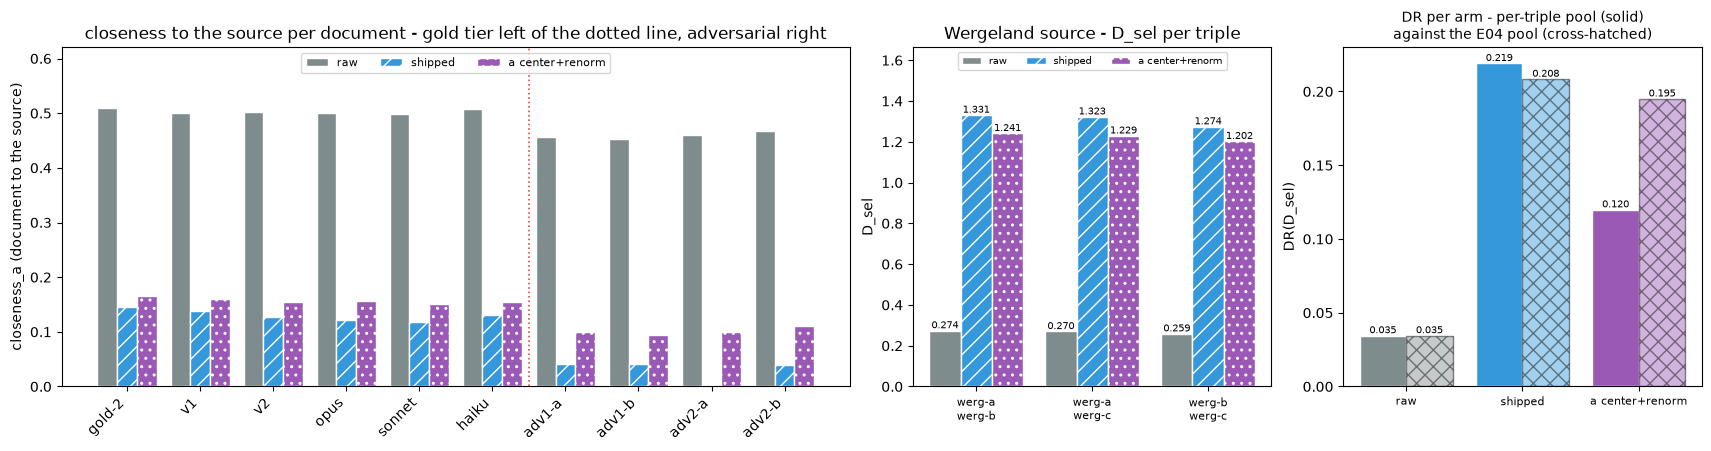

In [25]:
if PROCEED:
    fig, (ax_c, ax_w, ax_e) = plt.subplots(1, 3, figsize=(17, 4.4), constrained_layout=True,
                                           gridspec_kw={"width_ratios": [2.2, 1, 1]})
    x, w = np.arange(len(NONANCHOR)), 0.27
    for i, arm in enumerate(ARMS):
        ax_c.bar(x + (i - 1) * w, [CLOSE_A[arm][l] for l in NONANCHOR], w, color=ARM_COLOR[arm], hatch=ARM_HATCH[arm],
                 edgecolor="white", label=arm)
    ax_c.axvline(len(GOLD_NONANCHOR) - 0.5, color=C_ADV, ls=":", lw=1.2)
    ax_c.set_xticks(x)
    ax_c.set_xticklabels(NONANCHOR, rotation=45, ha="right")
    ax_c.set_ylabel("closeness_a (document to the source)")
    ax_c.set_title("closeness to the source per document - gold tier left of the dotted line, adversarial right")
    ax_c.set_ylim(0, max(CLOSE_A[RAW].values()) * 1.22)
    ax_c.legend(fontsize=8, loc="upper center", ncol=len(ARMS))

    xw = np.arange(len(WERG_KEYS))
    for i, arm in enumerate(ARMS):
        bars = ax_w.bar(xw + (i - 1) * w, [WERG[arm][k]["d_sel"] for k in WERG_KEYS], w, color=ARM_COLOR[arm],
                        hatch=ARM_HATCH[arm], edgecolor="white", label=arm)
        ax_w.bar_label(bars, fmt="%.3f", fontsize=7)
    ax_w.set_xticks(xw)
    ax_w.set_xticklabels([k.replace("|", "\n") for k in WERG_KEYS], fontsize=8)
    ax_w.set_ylabel("D_sel")
    ax_w.set_title("Wergeland source - D_sel per triple")
    ax_w.set_ylim(0, max(WERG[SHIPPED][k]["d_sel"] for k in WERG_KEYS) * 1.25)
    ax_w.legend(fontsize=7, loc="upper center", ncol=len(ARMS))

    xe = np.arange(len(ARMS))
    b1 = ax_e.bar(xe - 0.2, [PANEL[arm]["DR"] for arm in ARMS], 0.4, color=[ARM_COLOR[arm] for arm in ARMS], edgecolor="white")
    b2 = ax_e.bar(xe + 0.2, [E04_POOL[arm]["DR"] for arm in ARMS], 0.4, color=[ARM_COLOR[arm] for arm in ARMS],
                  edgecolor="black", alpha=0.45, hatch="xx")
    ax_e.bar_label(b1, fmt="%.3f", fontsize=7)
    ax_e.bar_label(b2, fmt="%.3f", fontsize=7)
    ax_e.set_xticks(xe)
    ax_e.set_xticklabels(ARMS, fontsize=8)
    ax_e.set_ylabel("DR(D_sel)")
    ax_e.set_title("DR per arm - per-triple pool (solid)\nagainst the E04 pool (cross-hatched)", fontsize=10)
    plt.show()
else:
    console.print(NOT_RUN)

## Guardrails

Each guardrail is measured, over every arm that was scored.

- **`V` 0/24** - the standing guardrail, read on the ibm symmetric panel of the primer: `smd` of each non-anchor summary to the anchor on the default path, 6 gold x 4 adversarial orderings. The primer's naive row is printed beside it
- **Raw embeddings** - every array compared byte for byte with its snapshot, after each arm and at the end
- **Default path** - `smd` and `order_gap` of the 55 ibm pairs, before against after, and against the baseline captured at commit `bd0002e`
- **`D_grd` untouched** - the grounding residual takes the reranker and entailment arrays and no embedding, so this guardrail holds by construction: no pre-pass can reach it. It is still measured. Every triple is scored once more per arm with the saved model-graded signals of E12-H69: `grd_a`, `grd_b` and `d_grd` must be bit-identical across the arms, `D_sel` must equal the embeddings-only call, and the signals file must keep its sha256
- **Metric property** - per arm, over the pooled statements of each of the 10 triples: unit norms, `cost = sqrt(2 - 2cos)`, and the triangle inequality over every statement triple. The largest deviation over the 10 triples is reported
- **Source tree** - `git status` on `src/` and `tests/`

In [26]:
# 1 - standing V on the ibm symmetric panel (default path, raw embeddings)
SYM = symmetric_panel(emb)
V_SYM_ZERO = SYM["V"] == 0

# 2 - raw embeddings byte-identical after every arm and at the end
RAW_UNCHANGED_END = raw_unchanged()
RAW_OK = bool(RAW_UNCHANGED_END and all(RAW_UNCHANGED_AFTER.values()))

# 3 - default path bit-identical: before against after, and after against the captured 1.1.5 baseline
DEFAULT_AFTER = default_path(emb_stem, IBM_PAIRS)
DEFAULT_IDENTICAL = DEFAULT_AFTER == DEFAULT_BEFORE
BASELINE_SMD_EQUAL = sum(DEFAULT_AFTER[k][0] == hexf(baseline["pairs"][k]["semantic"]["smd"]) for k in DEFAULT_AFTER)
BASELINE_GAP_EQUAL = sum(DEFAULT_AFTER[k][1] == hexf(baseline["pairs"][k]["structural"]["order_gap"]) for k in DEFAULT_AFTER)
DEFAULT_PATH_OK = bool(DEFAULT_IDENTICAL and BASELINE_SMD_EQUAL == len(IBM_PAIRS) and BASELINE_GAP_EQUAL == len(IBM_PAIRS))

# 4 - D_grd untouched: the saved model-graded signals through every arm
signals = np.load(SIGNALS_PATH)
R_SIG = {l: signals[f"R__{l}"] for l in labels}
ENT_SIG = {l: signals[f"ent__{l}"] for l in labels}
SIGNALS_SHAPE_OK = all(R_SIG[l].shape == (len(emb[l]), len(S)) and ENT_SIG[l].shape == (len(emb[l]),) for l in labels)
GRD = {}
for l in NONANCHOR:
    GRD[l] = {}
    for arm in ARMS_RUN:
        res = conditioned(ibm_triple(l, S), arm, reranker_a=R_SIG[l], reranker_b=R_SIG[ANCHOR],
                          entail_a=ENT_SIG[l], entail_b=ENT_SIG[ANCHOR])
        GRD[l][arm] = dict(grd_a=res.grd_a, grd_b=res.grd_b, d_grd=res.d_grd,
                           d_sel_equals_embeddings_only_call=hexf(res.d_sel) == hexf(PANEL[arm]["d_sel"][l]))
D_GRD_IDENTICAL = all(len({(hexf(v["grd_a"]), hexf(v["grd_b"]), hexf(v["d_grd"])) for v in GRD[l].values()}) == 1 for l in NONANCHOR)
D_GRD_EQUALS_DIRECT = all(hexf(GRD[l][RAW]["grd_a"]) == hexf(grounding_residual(R_SIG[l], ENT_SIG[l])) for l in NONANCHOR)
D_SEL_INDEPENDENT = all(v["d_sel_equals_embeddings_only_call"] for l in NONANCHOR for v in GRD[l].values())
SIGNALS_FILE_UNCHANGED = hashlib.sha256(SIGNALS_PATH.read_bytes()).hexdigest() == SIGNALS_SHA_BEFORE
GRD_SAVED_DIFF = max(abs(GRD[b][SHIPPED]["grd_a"] - baseline["grounded"][f"{STEM[a]}|{STEM[b]}"]["grd_b"]) for a, b in BASELINE_TRIPLES)
D_GRD_OK = bool(SIGNALS_SHAPE_OK and D_GRD_IDENTICAL and D_GRD_EQUALS_DIRECT and D_SEL_INDEPENDENT and SIGNALS_FILE_UNCHANGED)

# 5 - metric property per arm: the largest deviation over the 10 triples
METRIC = {}
for arm in ARMS_RUN:
    rows = [metric_property(arm_arrays(ibm_triple(l, S), arm)) for l in NONANCHOR]
    METRIC[arm] = dict(max_unit_norm_dev=max(r["max_unit_norm_dev"] for r in rows),
                       max_cost_identity_dev_float64=max(r["max_cost_identity_dev_float64"] for r in rows),
                       max_triangle_slack=max(r["max_triangle_slack"] for r in rows),
                       min_source_offdiag_cost=min(r["min_source_offdiag_cost"] for r in rows),
                       holds=all(r["holds"] for r in rows))
METRIC_OK = all(m["holds"] for m in METRIC.values())

# 6 - shipped source and tests unmodified; docs/ is listed for the record
tree = subprocess.run(["git", "-C", str(ROOT), "status", "--porcelain", "src", "tests"], capture_output=True, text=True).stdout.strip()
docs_tree = subprocess.run(["git", "-C", str(ROOT), "status", "--porcelain", "docs"], capture_output=True, text=True).stdout.strip()
SRC_UNTOUCHED = tree == ""

GUARDRAILS_OK = bool(V_SYM_ZERO and RAW_OK and DEFAULT_PATH_OK and D_GRD_OK and METRIC_OK and SRC_UNTOUCHED)
METRICS["guardrails"] = {
    "V_symmetric_panel": f"{SYM['V']}/{SYM['V_total']}", "V_symmetric_zero": V_SYM_ZERO,
    "symmetric_panel_naive_row": {k: SYM[k] for k in ("margin_pts", "dprime", "R", "DR", "V")}, "primer_naive_row": PRIMER_NAIVE,
    "raw_embeddings_byte_identical_after_each_arm": dict(RAW_UNCHANGED_AFTER), "raw_embeddings_byte_identical_at_end": RAW_UNCHANGED_END,
    "raw_embedding_arrays": len(RAW_BYTES), "raw_embedding_statements": int(sum(len(v) for v in RAW_ARRAYS.values())),
    "default_path_before_equals_after": DEFAULT_IDENTICAL, "default_path_pairs": len(IBM_PAIRS),
    "default_path_smd_equal_to_baseline": f"{BASELINE_SMD_EQUAL}/{len(IBM_PAIRS)}",
    "default_path_order_gap_equal_to_baseline": f"{BASELINE_GAP_EQUAL}/{len(IBM_PAIRS)}",
    "default_path_bit_identical": DEFAULT_PATH_OK,
    "d_grd": {"by_doc": GRD, "identical_across_arms": D_GRD_IDENTICAL, "equals_direct_grounding_residual": D_GRD_EQUALS_DIRECT,
              "d_sel_equals_embeddings_only_call": D_SEL_INDEPENDENT, "signals_shape_ok": SIGNALS_SHAPE_OK,
              "signals_file_sha256_unchanged": SIGNALS_FILE_UNCHANGED, "signals_file_sha256": SIGNALS_SHA_BEFORE,
              "max_abs_diff_to_saved_1_1_5_residuals": GRD_SAVED_DIFF, "untouched": D_GRD_OK},
    "metric_property": METRIC, "metric_property_holds": METRIC_OK,
    "git_status_src_tests": tree, "src_tests_untouched": SRC_UNTOUCHED, "git_status_docs": docs_tree,
    "arms_scored": list(ARMS_RUN), "all_hold": GUARDRAILS_OK,
}
KEY.update(V_symmetric_panel=f"{SYM['V']}/{SYM['V_total']}", symmetric_naive_margin_pts=SYM["margin_pts"],
           symmetric_naive_dprime=SYM["dprime"], symmetric_naive_R=SYM["R"], symmetric_naive_DR=SYM["DR"],
           d_grd_identical_across_arms=D_GRD_IDENTICAL, d_grd_max_abs_diff_to_saved_residuals=GRD_SAVED_DIFF,
           default_path_smd_equal_to_baseline=f"{BASELINE_SMD_EQUAL}/{len(IBM_PAIRS)}",
           default_path_order_gap_equal_to_baseline=f"{BASELINE_GAP_EQUAL}/{len(IBM_PAIRS)}")

t = Table(title="guardrails", header_style="bold medium_purple")
for col in ("guardrail", "reading", "holds"):
    t.add_column(col)
t.add_row("V - ibm symmetric panel (standing 0/24)",
          f"{SYM['V']}/{SYM['V_total']} | naive row: margin {SYM['margin_pts']:+.2f} pts, d' {SYM['dprime']:.2f}, R {SYM['R']:.3f}, "
          f"DR {SYM['DR']:.4f} | primer: margin {PRIMER_NAIVE['margin_pts']:+.2f}, d' {PRIMER_NAIVE['dprime']:.2f}, "
          f"R {PRIMER_NAIVE['R']:.3f}, DR {PRIMER_NAIVE['DR']:.4f}", yn(V_SYM_ZERO))
t.add_row("raw embeddings byte-identical",
          f"{len(RAW_BYTES)} arrays, {sum(len(v) for v in RAW_ARRAYS.values())} statements | after each arm: "
          + " | ".join(f"{a} {v}" for a, v in RAW_UNCHANGED_AFTER.items()) + f" | at the end: {RAW_UNCHANGED_END}", yn(RAW_OK))
t.add_row("default path - smd and order_gap",
          f"{len(IBM_PAIRS)} ibm pairs, before against after: {DEFAULT_IDENTICAL} | against the bd0002e baseline: smd "
          f"{BASELINE_SMD_EQUAL}/{len(IBM_PAIRS)}, order_gap {BASELINE_GAP_EQUAL}/{len(IBM_PAIRS)}", yn(DEFAULT_PATH_OK))
t.add_row("D_grd untouched (holds by construction)",
          f"grd_a, grd_b and d_grd bit-identical across {len(ARMS_RUN)} arms on {len(NONANCHOR)} triples: {D_GRD_IDENTICAL} | equal to "
          f"grounding_residual on the arrays: {D_GRD_EQUALS_DIRECT} | D_sel equal to the embeddings-only call: {D_SEL_INDEPENDENT} | "
          f"signals file sha256 unchanged: {SIGNALS_FILE_UNCHANGED} | largest difference to the 3 saved 1.1.5 residuals "
          f"{GRD_SAVED_DIFF:.2e}", yn(D_GRD_OK))
for arm, m in METRIC.items():
    t.add_row(f"metric property - {arm}",
              f"max unit-norm deviation {m['max_unit_norm_dev']:.1e} | max cost-identity deviation (float64) "
              f"{m['max_cost_identity_dev_float64']:.1e} | max triangle slack {m['max_triangle_slack']:+.1e} | "
              f"lowest source-to-source cost {m['min_source_offdiag_cost']:.4f}", yn(m["holds"]))
t.add_row("src/ and tests/ unmodified", escape(tree) or "(git status reports no modification)", yn(SRC_UNTOUCHED))
t.add_row("docs/ (for the record, not written by this notebook)", escape(docs_tree) or "(no modification)", "-")
console.print(Group(t, Panel(f"guardrails hold: [bold]{GUARDRAILS_OK}[/bold] | arms scored: {', '.join(ARMS_RUN)}",
                             border_style="dark_sea_green" if GUARDRAILS_OK else "indian_red")))

                                                                      guardrails                                                                      
┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━┓
┃ guardrail                                            ┃ reading                                                                             ┃ holds ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━┩
│ V - ibm symmetric panel (standing 0/24)              │ 0/24 | naive row: margin +4.71 pts, d' 4.68, R 1.670, DR 0.0873 | primer: margin    │ yes   │
│                                                      │ +4.71, d' 4.68, R 1.670, DR 0.0873                                                  │       │
│ raw embeddings byte-identical                        │ 16 arrays, 258 statements | after each arm: raw True | shipped True | a             │ yes   │
│                                                      │ center+renorm True | at the end: True                                               │       │
│ default path - smd and order_gap                     │ 55 ibm pairs, before against after: True | against the bd0002e baseline: smd 55/55, │ yes   │
│                                                      │ order_gap 55/55                                                                     │       │
│ D_grd untouched (holds by construction)              │ grd_a, grd_b and d_grd bit-identical across 3 arms on 10 triples: True | equal to   │ yes   │
│                                                      │ grounding_residual on the arrays: True | D_sel equal to the embeddings-only call:   │       │
│                                                      │ True | signals file sha256 unchanged: True | largest difference to the 3 saved      │       │
│                                                      │ 1.1.5 residuals 0.00e+00                                                            │       │
│ metric property - raw                                │ max unit-norm deviation 1.8e-07 | max cost-identity deviation (float64) 4.9e-08 |   │ yes   │
│                                                      │ max triangle slack +2.1e-15 | lowest source-to-source cost 0.0000                   │       │
│ metric property - shipped                            │ max unit-norm deviation 1.2e-07 | max cost-identity deviation (float64) 4.7e-08 |   │ yes   │
│                                                      │ max triangle slack +2.2e-16 | lowest source-to-source cost 0.0000                   │       │
│ metric property - a center+renorm                    │ max unit-norm deviation 1.2e-07 | max cost-identity deviation (float64) 6.0e-08 |   │ yes   │
│                                                      │ max triangle slack +9.4e-16 | lowest source-to-source cost 0.0000                   │       │
│ src/ and tests/ unmodified                           │ (git status reports no modification)                                                │ yes   │
│ docs/ (for the record, not written by this notebook) │ M docs/acc-crit-docdistance.md                                                      │ -     │
│                                                      │  M docs/defects-docdistance.md                                                      │       │
│                                                      │  M docs/experiments/wmd-docdistance-experiments.md                                  │       │
└──────────────────────────────────────────────────────┴─────────────────────────────────────────────────────────────────────────────────────┴───────┘
╭────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────╮
│ guardrails hold: True | arms scored: raw, shipped, a center+renorm      

## Prediction check

The record's prediction has three clauses. Each one is scored on its own line, for direction and for magnitude.
The two DR clauses have a direction in the record: shipped above raw, and arm a below shipped. The violation
clause predicts a count of 0 in every arm. A count cannot fall below 0, so that clause has no direction that
can fail; the bar counts a violation in arm a as not interchangeable. The hypothesis statement itself is that
arm a loses more than 10% of the `D_sel` dynamic range of the shipped pre-pass: DR(`D_sel`) under arm a below
0.9x the shipped arm.

In [27]:
if PROCEED:
    V_OBS = {arm: PANEL[arm]["V"] for arm in ARMS}
    PRED = {
        "selection-axis violations, raw | shipped | arm a": dict(
            predicted=f"{PRED_VIOLATIONS} | {PRED_VIOLATIONS} | {PRED_VIOLATIONS}",
            observed=f"{V_OBS[RAW]} | {V_OBS[SHIPPED]} | {V_OBS[ARM_A]}",
            direction="none that can fail: a count cannot fall below 0", direction_matched=None,
            held=bool(all(v == PRED_VIOLATIONS for v in V_OBS.values()))),
        "DR(D_sel) shipped / raw": dict(
            predicted=f">= {GATE_MIN_DR_RATIO}", observed=f"{DR_RATIO_SHIPPED_RAW:.4f}",
            direction="shipped above raw", direction_matched=bool(DR_SHIPPED > DR_RAW),
            held=bool(DR_RATIO_SHIPPED_RAW >= GATE_MIN_DR_RATIO)),
        "DR(D_sel) arm a / shipped": dict(
            predicted=f"{PRED_A_BAND[0]} .. {PRED_A_BAND[1]}", observed=f"{DR_RATIO_A_SHIPPED:.4f}",
            direction="arm a below shipped", direction_matched=bool(DR_A < DR_SHIPPED),
            held=bool(PRED_A_BAND[0] <= DR_RATIO_A_SHIPPED <= PRED_A_BAND[1])),
    }
    PRED_CLAUSES_HELD = sum(c["held"] for c in PRED.values())
    PRED_DIRECTION_MATCHED = all(c["direction_matched"] for c in PRED.values() if c["direction_matched"] is not None)
    HYPOTHESIS_STATEMENT_HELD = bool(DR_RATIO_A_SHIPPED < BAR_DR_RATIO)     # arm a loses more than 10% of the shipped range
    NOT_HELD = [k for k, c in PRED.items() if not c["held"]]
    METRICS["prediction_check"] = {
        "clauses": PRED, "clauses_held": f"{PRED_CLAUSES_HELD}/{len(PRED)}", "all_clauses_held": PRED_CLAUSES_HELD == len(PRED),
        "clauses_not_held": NOT_HELD, "direction_matched_on_clauses_with_a_direction": PRED_DIRECTION_MATCHED,
        "hypothesis_statement_held": HYPOTHESIS_STATEMENT_HELD,
    }
    t = Table(title="registered prediction, clause by clause", header_style="bold medium_purple")
    for col in ("clause", "predicted", "observed", "direction in the record", "direction matched", "held"):
        t.add_column(col)
    for k, c in PRED.items():
        t.add_row(k, c["predicted"], c["observed"], c["direction"],
                  "-" if c["direction_matched"] is None else yn(c["direction_matched"]), yn(c["held"]))
    console.print(Group(t, Panel(
        f"clauses held: [bold]{PRED_CLAUSES_HELD}/{len(PRED)}[/bold] | direction matched on the two clauses that have one: "
        f"[bold]{PRED_DIRECTION_MATCHED}[/bold] | hypothesis statement held (DR arm a below {BAR_DR_RATIO}x shipped): "
        f"[bold]{HYPOTHESIS_STATEMENT_HELD}[/bold]\n"
        f"clauses not held: {'; '.join(NOT_HELD) or 'none'} - arm a reads {V_OBS[ARM_A]} against a predicted {PRED_VIOLATIONS}; "
        f"the bar counts a violation in arm a as not interchangeable",
        border_style="dark_sea_green" if PRED_DIRECTION_MATCHED and HYPOTHESIS_STATEMENT_HELD else "indian_red")))
else:
    console.print(NOT_RUN)

                                                       registered prediction, clause by clause                                                        
┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━┓
┃ clause                                        ┃ predicted  ┃ observed  ┃ direction in the record                        ┃ direction matched ┃ held ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━┩
│ selection-axis violations, raw | shipped |    │ 0 | 0 | 0  │ 0 | 0 | 1 │ none that can fail: a count cannot fall below  │ -                 │ no   │
│ arm a                                         │            │           │ 0                                              │                   │      │
│ DR(D_sel) shipped / raw                       │ >= 1.5     │ 6.3433    │ shipped above raw                              │ yes               │ yes  │
│ DR(D_sel) arm a / shipped                     │ 0.3 .. 0.9 │ 0.5471    │ arm a below shipped                            │ yes               │ yes  │
└───────────────────────────────────────────────┴────────────┴───────────┴────────────────────────────────────────────────┴───────────────────┴──────┘
╭────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────╮
│ clauses held: 2/3 | direction matched on the two clauses that have one: True | hypothesis statement held (DR arm a below 0.9x shipped): True       │
│ clauses not held: selection-axis violations, raw | shipped | arm a - arm a reads 1 against a predicted 0; the bar counts a violation in arm a as   │
│ not interchangeable                                                                                                                                │
╰────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────╯

## Acceptance bar

The registered bar, applied as written. Confirmed (not interchangeable) iff DR(`D_sel`) under arm a is below
0.9x the shipped arm or arm a reads at least one selection-axis violation. Refuted (interchangeable) iff arm a
reads 0 violations and DR(`D_sel`) under arm a is at least 0.9x the shipped arm. The two outcomes are
complements. The decision rule recorded with the bar: ACC-GEOM-21 changes the conditioned-path pre-pass only on
Refuted.

In [28]:
if PROCEED:
    DR_BELOW_BAR = bool(DR_RATIO_A_SHIPPED < BAR_DR_RATIO)
    A_HAS_VIOLATION = bool(V_A >= BAR_MIN_VIOLATIONS)
    NOT_INTERCHANGEABLE = bool(DR_BELOW_BAR or A_HAS_VIOLATION)
    BAR_MET = bool(NOT_INTERCHANGEABLE and GUARDRAILS_OK)
    METRICS["acceptance"] = {
        "bar": f"Confirmed (not interchangeable) iff DR(D_sel) arm a < {BAR_DR_RATIO}x shipped OR arm a reads >= 1 violation; "
               f"Refuted (interchangeable) iff arm a reads 0 violations AND DR(D_sel) arm a >= {BAR_DR_RATIO}x shipped; guardrails hold",
        "met": BAR_MET, "not_interchangeable": NOT_INTERCHANGEABLE, "guardrails_hold": GUARDRAILS_OK,
        "readings": {
            "dr_shipped": DR_SHIPPED, "dr_arm_a": DR_A, "dr_ratio_arm_a_over_shipped": DR_RATIO_A_SHIPPED,
            "bar_dr_ratio": BAR_DR_RATIO, "dr_arm_a_below_bar": DR_BELOW_BAR,
            "violations_arm_a": V_A, "violation_orderings": PANEL[ARM_A]["V_total"], "arm_a_has_violation": A_HAS_VIOLATION,
        },
        "second_readings": {
            "violations_arm_a_without_anchor": f"{PANEL[ARM_A]['V_without_anchor']}/{PANEL[ARM_A]['V_without_anchor_total']}",
            "exchanged_argument_order_dr_ratio_arm_a_over_shipped": SWAPPED_RATIO_A_SHIPPED,
            "exchanged_argument_order_violations_arm_a": v_text(SWAPPED[ARM_A]),
        },
    }
    t = Table(title="acceptance bar - arm a against the shipped pre-pass on the selection axis", header_style="bold medium_purple")
    for col in ("clause", "reading", "threshold", "clause true"):
        t.add_column(col, justify="left" if col in ("clause", "clause true") else "right")
    t.add_row("DR(D_sel) arm a / shipped below the bar", f"{DR_RATIO_A_SHIPPED:.4f}", f"< {BAR_DR_RATIO}", yn(DR_BELOW_BAR))
    t.add_row("arm a reads at least one violation", v_text(PANEL[ARM_A]), f">= {BAR_MIN_VIOLATIONS}", yn(A_HAS_VIOLATION))
    console.print(Group(t, Panel(
        f"not interchangeable (either clause true): [bold]{NOT_INTERCHANGEABLE}[/bold] | guardrails hold: [bold]{GUARDRAILS_OK}[/bold] | "
        f"bar met: [bold]{BAR_MET}[/bold]\n"
        f"second readings beside the bar: violations arm a without the anchor "
        f"{PANEL[ARM_A]['V_without_anchor']}/{PANEL[ARM_A]['V_without_anchor_total']} | exchanged argument order (a = anchor): "
        f"DR arm a / shipped {SWAPPED_RATIO_A_SHIPPED:.4f}, violations arm a {v_text(SWAPPED[ARM_A])}",
        title="E14-H76 acceptance", border_style="dark_sea_green" if BAR_MET else "indian_red")))
else:
    console.print(NOT_RUN)

   acceptance bar - arm a against the shipped pre-pass on the selection axis   
┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━┳━━━━━━━━━━━┳━━━━━━━━━━━━━┓
┃ clause                                  ┃ reading ┃ threshold ┃ clause true ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━╇━━━━━━━━━━━╇━━━━━━━━━━━━━┩
│ DR(D_sel) arm a / shipped below the bar │  0.5471 │     < 0.9 │ yes         │
│ arm a reads at least one violation      │    1/28 │      >= 1 │ yes         │
└─────────────────────────────────────────┴─────────┴───────────┴─────────────┘
╭──────────────────────────────────────────────────────────────── E14-H76 acceptance ────────────────────────────────────────────────────────────────╮
│ not interchangeable (either clause true): True | guardrails hold: True | bar met: True                                                             │
│ second readings beside the bar: violations arm a without the anchor 1/24 | exchanged argument order (a = anchor): DR arm a / shipped 0.5471,       │
│ violations arm a 1/28                                                                                                                              │
╰────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────╯

## Verdict and metrics JSON

The verdict follows the campaign vocabulary in a fixed order: a fired kill-gate gives `Killed-at-gate`; a
failed harness reading (executor's rule) or a failed guardrail gives `Blocked`; the first branch of the bar gives `Confirmed`
(not interchangeable); the second gives `Refuted` (interchangeable). The decision-rule outcome for
ACC-GEOM-21 is true only on `Refuted`. The key numbers are printed at full precision so that every number of
the campaign result JSON is copied from an output of this run, and every measured number is written to
`reports/E14-H76-conditioned-centering-probe-metrics.json`.

In [29]:
if not GATE_PASSED:
    VERDICT = "Killed-at-gate"
elif not HARNESS_OK:
    VERDICT = "Blocked"
elif not GUARDRAILS_OK:
    VERDICT = "Blocked"
elif NOT_INTERCHANGEABLE:
    VERDICT = "Confirmed"
else:
    VERDICT = "Refuted"

GEOM21_CHANGES = VERDICT == "Refuted"
KEY["geom21_changes_conditioned_prepass"] = GEOM21_CHANGES
METRICS["verdict"] = VERDICT
METRICS["decision_rule"] = {"rule": "ACC-GEOM-21 changes the conditioned-path pre-pass only on Refuted",
                            "geom21_changes_conditioned_prepass": GEOM21_CHANGES}
METRICS["result_key_numbers"] = KEY
METRICS_PATH.write_text(json.dumps(METRICS, indent=2, ensure_ascii=False, default=lambda o: o.item()), encoding="utf-8")
print(f"verdict = {VERDICT}\n"
      f"geom21_changes_conditioned_prepass = {GEOM21_CHANGES}\n"
      f"wrote {METRICS_PATH.relative_to(ROOT)} ({METRICS_PATH.stat().st_size} bytes)\n"
      f"key_numbers =\n{json.dumps(KEY, indent=2, default=lambda o: o.item())}\n"
      f"acceptance =\n{json.dumps(METRICS.get('acceptance', {}), indent=2)}\n"
      f"kill_gate =\n{json.dumps(METRICS['kill_gate'], indent=2)}")

verdict = Confirmed
geom21_changes_conditioned_prepass = False
wrote reports/E14-H76-conditioned-centering-probe-metrics.json (81909 bytes)
key_numbers =
{
  "n_documents": 10,
  "n_source_statements": 70,
  "pool_statements_min": 81,
  "pool_statements_max": 93,
  "source_share_of_pool_min": 0.7526881720430108,
  "source_share_of_pool_max": 0.8641975308641975,
  "dr_raw": 0.0345353419991734,
  "dr_shipped": 0.21906737683021127,
  "dr_ratio_shipped_over_raw": 6.343280944936193,
  "violations_raw": 0,
  "violations_shipped": 0,
  "violation_orderings": 28,
  "violations_raw_without_anchor": 0,
  "violations_shipped_without_anchor": 0,
  "sel_margin_raw": 0.008483411208983833,
  "sel_margin_shipped": 0.04321458386089477,
  "shipped_equals_saved_results": true,
  "replacement_route_equals_shipped": true,
  "swapped_order_dr_ratio_shipped_over_raw": 6.343280884373915,
  "swapped_order_max_abs_d_sel_diff_raw": 6.393625677503234e-09,
  "swapped_order_max_abs_d_sel_diff_shipped": 8.0022029003

## Conclusions

**Centering plus renormalisation is not interchangeable with the shipped pre-pass on the conditioned selection axis.**
On the 10 ibm triples `{document, anchor, source}`, DR(`D_sel`) under arm a is 0.5471x the shipped arm (0.119861
against 0.219067; bar: below 0.9x), and arm a reads 1/28 selection-axis violations where the shipped arm reads
0/28. Either clause alone gives the first branch of the bar. Verdict: **Confirmed**. By the decision rule recorded
with the bar, ACC-GEOM-21 does not change the conditioned-path pre-pass: the shipped `all_but_the_top(k=1)` stays.

**Definitions** - the scored `DR`, `violations` and `contrast` functions equal the E04 text character for character
(text check True, True, True). `violations` runs over 28 orderings because the E04 `gold_labels` list holds the
anchor. The anchor's `D_sel` against itself is 0.0, so the count over the 24 orderings without the anchor is the
same number in every arm: 0/24, 0/24 and 1/24.

**Kill-gate** - passed

- DR(`D_sel`) raw 0.034535, shipped 0.219067: shipped / raw = 6.3433 against a kill threshold of 1.5
- Violations in the shipped arm 0/28 (0/24 without the anchor); raw arm 0/28
- The shipped INT8 path with the per-triple pool shows the E04-H15 property

**Harness readings** (executor's rule, stated in the configuration cell) - passed

- The shipped call reproduces the three saved 1.1.5 results bit for bit: five numbers, both coverage profiles and the statement counts of `gold|v1`, `gold|adv1-a` and `gold|adv2-b`
- `all_but_the_top(k=1)` built outside the function and passed with `anisotropy=False` equals the internal pre-pass bit for bit on 10/10 triples, so the route used for arm a replaces the pre-pass and nothing else
- Second reading of the argument order: with the two documents exchanged (`a` = anchor), `D_sel` moves by at most 8.002e-08 and the readings of the gate and the bar are the same: shipped / raw 6.3433, arm a / shipped 0.5471, arm a 1/28

**Registered experiment** - 10 documents, per-triple pool of 81 to 93 statements, source share 0.753 to 0.864

| arm | DR(`D_sel`) | DR / raw | DR / shipped | violations | lowest adversarial - highest gold |
|---|---|---|---|---|---|
| raw | 0.034535 | 1.0000 | 0.1576 | 0/28 | +0.008483 |
| shipped | 0.219067 | 6.3433 | 1.0000 | 0/28 | +0.043215 |
| a center+renorm | 0.119861 | 3.4707 | 0.5471 | 1/28 | -0.004160 |

- **Arm a reads about half of the shipped dynamic range.** Per document, `D_sel` under arm a is 0.330 to 0.502 times the shipped value. E14-H75 read 0.330 to 0.493 on three of these triples; the full panel reproduces it
- **Arm a reverses one ordering between the tiers.** `haiku` (gold tier) reads 0.140584 and `adv2-b` (adversarial) reads 0.136424, so the gold document is farther from the anchor than the adversarial one. Under the shipped arm the same two documents read 0.370615 and 0.413829. The lowest adversarial minus the highest gold `D_sel` is +0.043215 shipped and -0.004160 under arm a
- **The order of the documents is nearly the same.** Spearman of `D_sel` between arm a and shipped is 0.9758 over the 10 documents: two pairs of neighbours exchange rank (`gold-2` with `sonnet`, `haiku` with `adv2-b`). The difference is in the scale of `D_sel` and in that one ordering

**Prediction** - 2/3 clauses held; the direction matched on the two clauses that have one

- Held, direction and magnitude: shipped / raw 6.3433 (predicted at least 1.5, shipped above raw); arm a / shipped 0.5471 (predicted 0.3 to 0.9, arm a below shipped)
- Not held: 0 violations in all three arms. Arm a reads 1. A count cannot fall below 0, so this clause has no direction that can fail; the bar counts a violation in arm a as not interchangeable. The effect on arm a is larger than predicted

**Readings without a bar**

- **Contrast** (mean adversarial / mean gold `D_sel`): raw 4.5066, shipped 2.4134, arm a 2.8565. Both pre-passes lower the contrast against raw. Arm a reads a higher contrast than shipped and a violation, so the contrast does not indicate whether the tiers are separated
- **Distance to the source.** Arm a raises `closeness_a` of every document against the shipped arm: by 0.0194 to 0.0342 for the gold tier and by 0.0531 to 0.1002 for the adversarial tier. The largest difference is 0.100227 (10.02 closeness points) at `adv2-a`. The mean closeness difference between the tiers is +0.0997 shipped and +0.0553 under arm a. Under the shipped arm `adv2-a` has residual 1.4150, above `sqrt(2)`, so its closeness is clipped to 0; no residual reaches `sqrt(2)` under arm a or raw
- **E04 pool.** With one pre-pass over all 11 summaries plus the source (168 statements), arm a reads DR 0.195024 against 0.208385 shipped: 0.9359x at 0/28 violations. The loss measured above belongs to the per-triple pool, and the per-triple pool is the one that ships
- **Wergeland source** (52 statements through the shipped reader, three sections, three triples): `D_sel` under arm a is 0.930 to 0.944 times the shipped value, and the order of the three triples is the same in all three arms. The three shipped values lie between 1.274138 and 1.331129, so their standard deviation (0.025085 shipped, 0.016175 arm a) is not a dynamic-range reading

**Mechanism** - the outputs show a different cause than the registered one

- The record expected a centered PC1 nearly orthogonal to the mean direction (0.056 on the 76-statement symmetric pool of E14-H75) and a projection that removes content variance of the source. In the 10 per-triple pools `cos(centered PC1, mean direction)` is 0.2499 to 0.3091, PC1 carries a share of 0.6835 to 0.6921 of the centered variance, and a share of 0.8846 to 0.9200 of the PC1 energy is on source statements
- **PC1 separates markup statements from prose.** The shipped reader (`markdown=False`) segments the ibm source into 70 statements, of which 22 are one word: `'-'` 13 times, `'###'` 6 times, `'##'` twice, `'Overview'` once. On the signed PC1 these 22 read +0.709 to +0.868, every document and anchor statement reads -0.443 to -0.230, and the 48 source statements of two words or more read -0.434 to +0.521. The 11 summaries hold no one-word statement
- **Centering alone leaves the prose statements close to each other.** The pooled mean lies between the two groups, so after centering every prose statement keeps a common component along PC1. The mean ground cost between two source statements of two words or more is 0.6081 raw, 1.1608 under arm a and 1.4110 under the shipped arm (`sqrt(2)` = 1.4142 is the cost at cosine 0). Removing PC1 removes that common component; centering does not
- **Counterfactual, two word rules.** The ratio of arm a to shipped follows the short statements of the source:

| source | statements | DR raw | DR shipped | DR arm a | arm a / shipped | violations arm a | PC1 share of centered variance |
|---|---|---|---|---|---|---|---|
| registered | 70 | 0.034535 | 0.219067 | 0.119861 | 0.5471 | 1/28 | 0.6835 to 0.6921 |
| fewer than 2 words removed | 48 | 0.034541 | 0.262116 | 0.240237 | 0.9165 | 0/28 | 0.2980 to 0.3211 |
| fewer than 5 words removed | 42 | 0.034619 | 0.152500 | 0.263025 | 1.7248 | 0/28 | 0.1866 to 0.2006 |

- With the 22 one-word statements removed, the mean ground cost between source statements under arm a is 1.4071 against 1.4140 shipped, and arm a reads 0.9165x the shipped DR
- With the 28 statements of fewer than 5 words removed, `cos(centered PC1, mean direction)` is 0.0058 to 0.0865, the geometry the record cites. There the projection lowers the dynamic range: shipped 0.152500 against 0.263025 under arm a (1.7248x). The shipped arm reads the larger distance between the tiers there: lowest adversarial minus highest gold +0.155992 against +0.069921
- The shipped DR itself reads 0.219067, 0.262116 and 0.152500 on the three sources. The raw DR does not move (0.034535, 0.034541, 0.034619)
- **Nearest source statement.** 60 of 88 document statements have the same nearest source statement under arm a and under shipped (raw and shipped 51/88, arm a and raw 79/88). The projection changes the assignment of 28 statements, as the record predicted; the component it removes is the markup one

**Guardrails** - all hold

- `V` 0/24 on the ibm symmetric panel; its naive row reads margin +4.71 points, d' 4.68, R 1.670, DR 0.0873, which is the primer's row
- Raw embeddings byte-identical after each of the three arms and at the end: 16 arrays, 258 statements
- Default-path `smd` and `order_gap` bit-identical before and after on 55 ibm pairs, and equal to the `bd0002e` baseline 55/55 and 55/55
- `D_grd` untouched. This guardrail holds by construction, because the residual is computed from the reranker and entailment arrays alone. Measured: `grd_a`, `grd_b` and `d_grd` from the saved E12-H69 signals are bit-identical across the three arms on 10 triples and differ from the three saved 1.1.5 residuals by 0.00e+00; `D_sel` equals the embeddings-only call; the signals file keeps its sha256
- Metric property in all three arms over the 10 pooled triples: unit norms to 1.8e-07 at most, `cost = sqrt(2 - 2cos)` to 6.0e-08 at most in float64 on exact-unit copies, triangle slack +2.1e-15 at most
- `git status` reports no modification under `src/` and `tests/`. The three modified files under `docs/` are the orchestrator's; this notebook writes nothing there

**Limits**

- The bar is read on one source and one anchor: 10 documents, 6 gold and 4 adversarial. The violation is one ordering, by 0.004160
- The section on the first principal component is not in the registered record and has no bar. It was added after the first execution of this notebook showed the PC1 share, and its two word rules were chosen with those outputs in view. The counterfactuals remove rows from the encoded source; they do not re-segment with `markdown=True` and do not run the shipped `min_words` option through the pipeline
- The bar is one-sided: it reads arm a below 0.9x. With the statements of fewer than 5 words removed arm a reads 1.7248x, which the bar does not count as a difference
- The lowest ground cost between two different source statements is 0.0000 in every arm, the raw one included: the 70 statements hold 52 distinct texts. `D_sel` therefore reads 0 between two coverage profiles that differ only between repeated statements. No arm changes that
- The Wergeland source holds 3 one-word statements of 52, and its PC1 carries a share of 0.3904 to 0.4020 of the centered variance. What that component separates was not read. The fixture has no tiers, so it gives no violation count
- The tolerance for the cost identity is the E12-H64 reading (float64, exact-unit copies), an executor's rule stated in the configuration cell; the record names no tolerance

**Consequence.** The decision-rule outcome for ACC-GEOM-21 is `geom21_changes_conditioned_prepass = False`: on the
conditioned path the shipped `all_but_the_top(k=1)` stays, because centering alone reads 0.5471x of its `D_sel`
dynamic range and one violation. The cause is narrower than the record assumed. On this fixture the projection
removes the component of the one-word markup statements (22 of 70 source statements), not content of the source.
How the two pre-passes compare depends on which short statements the source holds: arm a reads 0.5471x, 0.9165x
and 1.7248x the shipped DR on the registered source, with statements of fewer than 2 words removed and with
statements of fewer than 5 words removed. Whether the conditioned path should keep such statements out of the
source is a separate question that this notebook does not decide.